In [49]:
%load_ext autoreload
%autoreload 2

import os
import sys
module_path = os.path.abspath(os.path.join('../..'))
if module_path not in sys.path:
    sys.path.append(module_path)

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import jax
import seaborn as sns

jax.config.update('jax_platforms', 'cpu')

plt.rcParams['font.family'] = 'Helvetica Light'

from behavioral_plotting import (
    plot_session,
    load_odor_site_df,
    plot_patch_statistics_per_session,
    plot_patch_statistics_across_dfs,
    plot_patch_statistics,
    plot_multi_df_accuracy_heatmap,
    plot_leave_probabilities,
    append_index_phase,
    plot_grouped_mean_std,
    plot_stop_fraction,
    plot_first_patch_rewards_vs_other_prefactors,
    plot_rewards_by_patch_sequence,
    odor_colors,
)
from aux_funcs import format_plot
from nb_analysis_tools import *

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [21]:
# had to clear the font cache to get the Helvetica Light font to work.
# If you see a warning about missing fonts, run this cell and restart the kernel.

# import matplotlib as mpl
# import shutil, os

# # Find and delete the font cache
# cache_dir = mpl.get_cachedir()
# print(f"Cache dir: {cache_dir}")

# # Delete cache files
# for f in os.listdir(cache_dir):
#     if f.endswith('.json') or f.endswith('.cache'):
#         os.remove(os.path.join(cache_dir, f))
#         print(f"Deleted: {f}")

# print("Done — restart the kernel now")

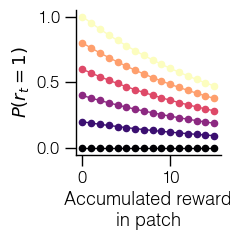

In [4]:
# ── Exponential decay curves ──────────────────────────────────────────────
prefactors  = [0,  0.2, 0.4, 0.6, 0.8, 1]   # one per curve
decay_rates = [1/20] * 6   # one per curve

x = np.arange(16)   # 0 through 20

fig, ax = plt.subplots(figsize=(2.5, 2.5))
for prefactor, decay_rate in zip(prefactors, decay_rates):
    color = mpl.colormaps['magma'](prefactors.index(prefactor) / (len(prefactors) - 1))
    y = prefactor * np.exp(-decay_rate * x)
    ax.plot(x, y, color=color, lw=1)
    ax.scatter(x, y, color=color, s=20)
ax.set_xlabel('Accumulated reward\nin patch')
ax.set_ylabel(r'$P(r_t=1)$')
format_plot(ax)
plt.tight_layout()
plt.show()

In [74]:
CURRICULUM_TRAINED_NETWORKS_PRE_SWITCH = [
    '../../../results/curriculum_trained_gru_coupled_to_fixed/step_00/traj_000499.pkl',
]

CURRICULUM_TRAINED_NETWORKS = [
    # '../../../results/curriculum_trained_gru_coupled_to_fixed/step_00/traj_000499.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed/step_01/traj_000500.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed/step_01/traj_000505.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed/step_01/traj_000510.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed/step_01/traj_000515.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed/step_01/traj_000520.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed/step_01/traj_000525.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed/step_01/traj_000530.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed/step_01/traj_000535.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed/step_01/traj_000540.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed/step_01/traj_000545.pkl',
]

CURRICULUM_TRAINED_NETWORKS_FIXED_TO_COUPLED = [
    '../../../results/curriculum_trained_gru_fixed_to_coupled/step_01/traj_000500.pkl',
    '../../../results/curriculum_trained_gru_fixed_to_coupled/step_01/traj_000505.pkl',
    '../../../results/curriculum_trained_gru_fixed_to_coupled/step_01/traj_000510.pkl',
    '../../../results/curriculum_trained_gru_fixed_to_coupled/step_01/traj_000515.pkl',
    '../../../results/curriculum_trained_gru_fixed_to_coupled/step_01/traj_000520.pkl',
]


CURRICULUM_TRAINED_NETWORKS_MULTISTAGE_CYCLIC = [
    # '../../../results/curriculum_trained_gru_coupled_to_fixed/step_00/traj_000499.pkl',
    '../../../results/multi_stage_exp_gru_initial_prob_offset_coupled_retrain/step_01/traj_000500.pkl',
    '../../../results/multi_stage_exp_gru_initial_prob_offset_coupled_retrain/step_01/traj_000515.pkl',
    '../../../results/multi_stage_exp_gru_initial_prob_offset_coupled_retrain/step_02/traj_000550.pkl',
    '../../../results/multi_stage_exp_gru_initial_prob_offset_coupled_retrain/step_02/traj_000565.pkl',
    '../../../results/multi_stage_exp_gru_initial_prob_offset_coupled_retrain/step_03/traj_000600.pkl',
    '../../../results/multi_stage_exp_gru_initial_prob_offset_coupled_retrain/step_03/traj_000615.pkl',
    '../../../results/multi_stage_exp_gru_initial_prob_offset_coupled_retrain/step_04/traj_000650.pkl',
    '../../../results/multi_stage_exp_gru_initial_prob_offset_coupled_retrain/step_04/traj_000665.pkl',
]

CURRICULUM_TRAINED_NETWORKS_FIXED_TO_EQUAL_LOW = [
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_00/traj_000499.pkl',
    
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_01/traj_000500.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_01/traj_000510.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_01/traj_000520.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_01/traj_000530.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_01/traj_000540.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_01/traj_000550.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_01/traj_000560.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_01/traj_000570.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_01/traj_000580.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_01/traj_000590.pkl',

    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_02/traj_000600.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_02/traj_000610.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_02/traj_000620.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_02/traj_000630.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_02/traj_000640.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_02/traj_000650.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_02/traj_000660.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_02/traj_000670.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_02/traj_000680.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal/step_02/traj_000690.pkl',
]

CURRICULUM_TRAINED_NETWORKS_FIXED_TO_EQUAL_HIGH = [
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_00/traj_000499.pkl',
    
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_01/traj_000500.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_01/traj_000510.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_01/traj_000520.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_01/traj_000530.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_01/traj_000540.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_01/traj_000550.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_01/traj_000560.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_01/traj_000570.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_01/traj_000580.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_01/traj_000590.pkl',

    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_02/traj_000600.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_02/traj_000610.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_02/traj_000620.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_02/traj_000630.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_02/traj_000640.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_02/traj_000650.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_02/traj_000660.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_02/traj_000670.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_02/traj_000680.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_to_equal_high/step_02/traj_000690.pkl',
]


CURRICULUM_TRAINED_NETWORKS_V2 = [
    '../../../results/curriculum_trained_gru_coupled_to_fixed_v2/step_00/traj_000249.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_v2/step_00/traj_000299.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_v2/step_00/traj_000349.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_v2/step_00/traj_000399.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_v2/step_00/traj_000449.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_v2/step_00/traj_000499.pkl',

    '../../../results/curriculum_trained_gru_coupled_to_fixed_v2/step_01/traj_000500.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_v2/step_01/traj_000550.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_v2/step_01/traj_000600.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_v2/step_01/traj_000650.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_v2/step_01/traj_000700.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_v2/step_01/traj_000750.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_v2/step_01/traj_000800.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_v2/step_01/traj_000850.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_v2/step_01/traj_000900.pkl',
    '../../../results/curriculum_trained_gru_coupled_to_fixed_v2/step_01/traj_000950.pkl',
]


## Behavioral traces

[0.15360713 0.1667553  0.5713192 ]


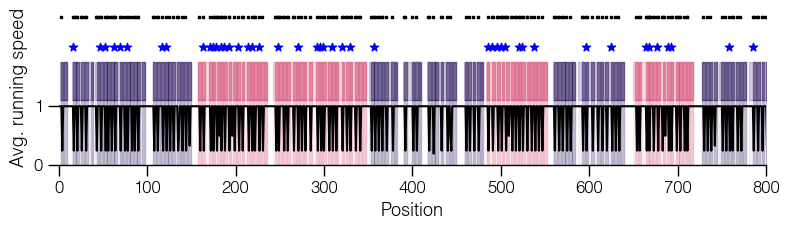

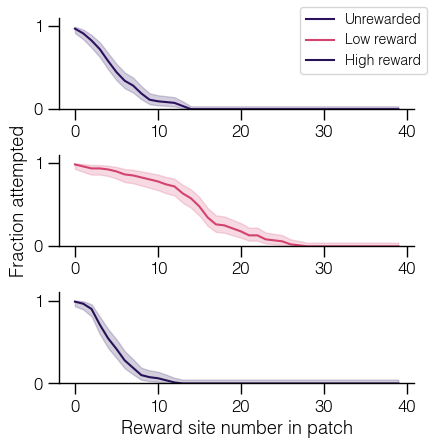

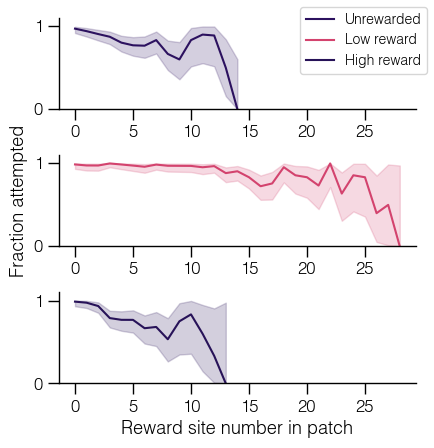

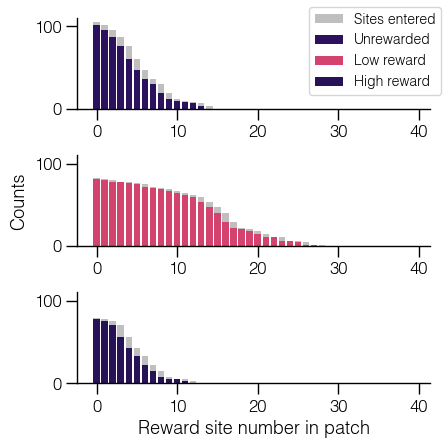

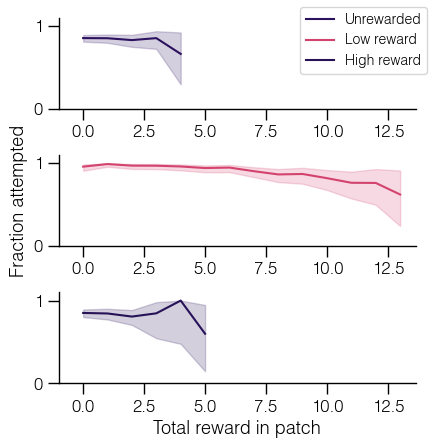

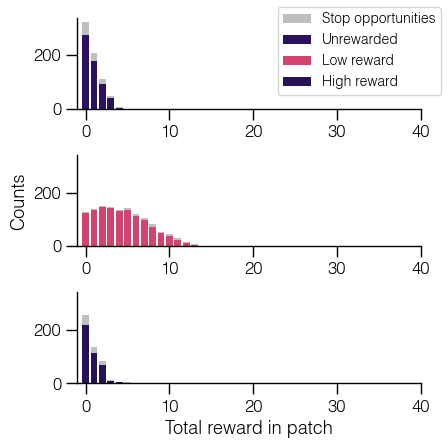

In [15]:
for i, data_path in enumerate(CURRICULUM_TRAINED_NETWORKS_PRE_SWITCH):
    plot_session(
        data_path,
        session_idx=0,
        xlim=(0, 800),
        max_reward_param=40,
        max_reward_sites=30,
        use_fixed_colors=False,
        color_by_reward_param=False
    )

[0.  0.6 0.8]
[0.  0.6 0.8]
[0.  0.6 0.8]
[0.  0.6 0.8]


/home/david.bell/work/favorably_connected_2/code/behavioral_plotting.py:158: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(3, 1, figsize=(3 * scale, 3 * scale), sharex=True, sharey=True)


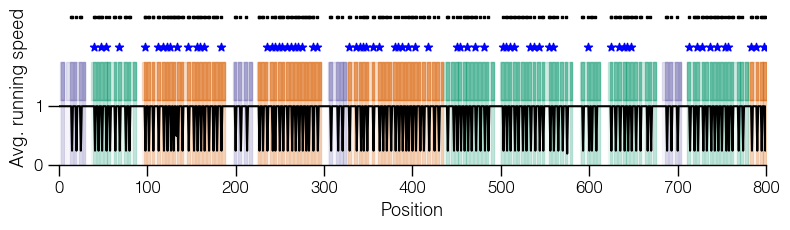

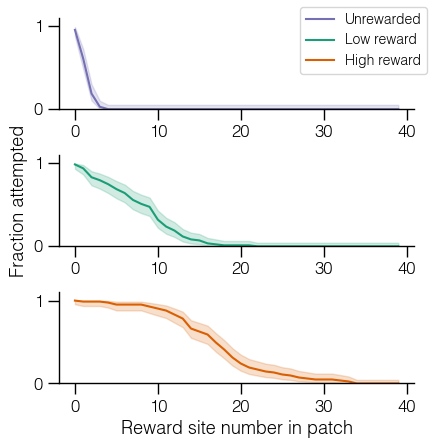

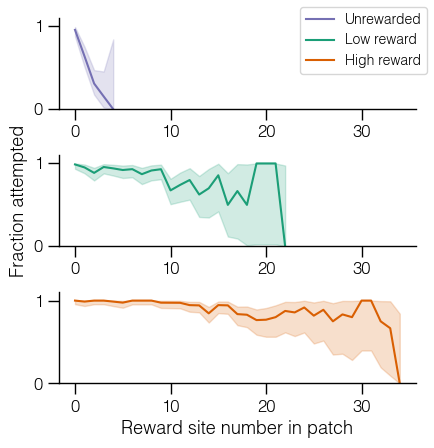

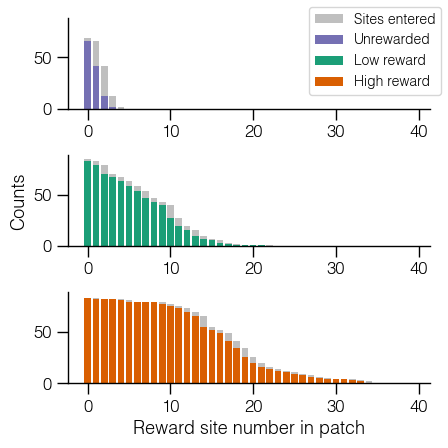

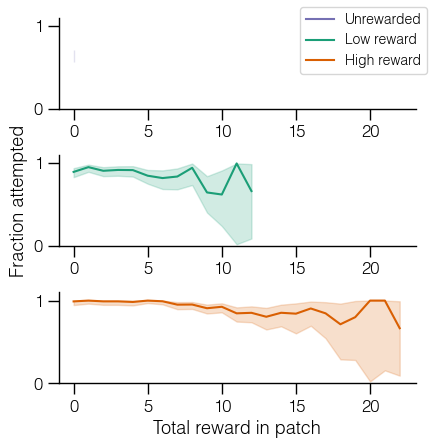

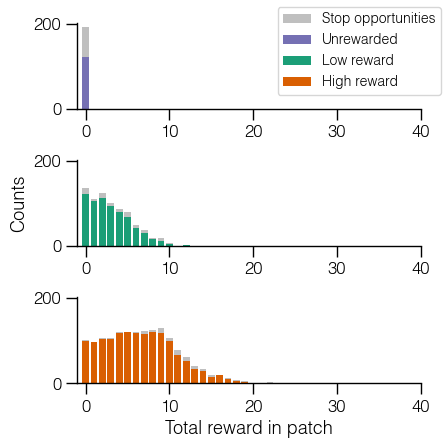

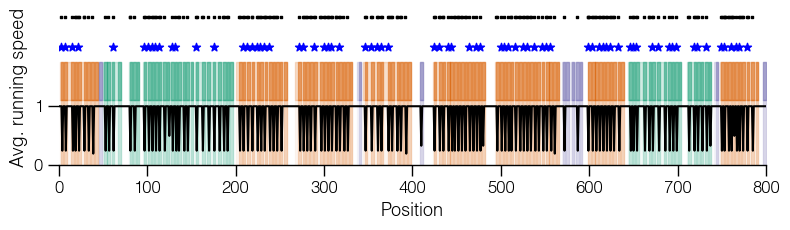

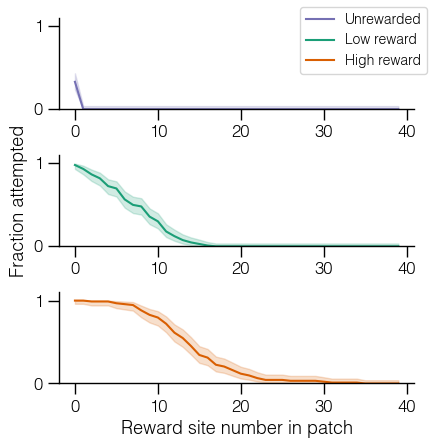

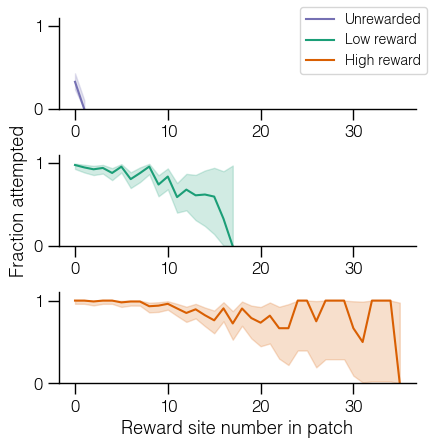

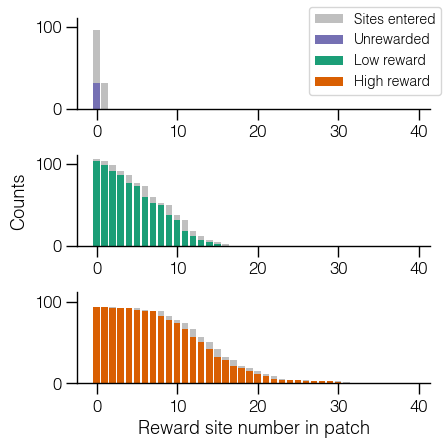

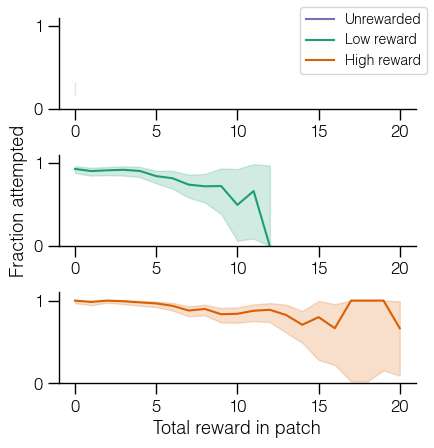

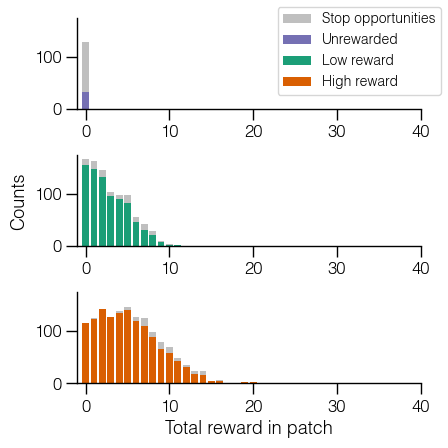

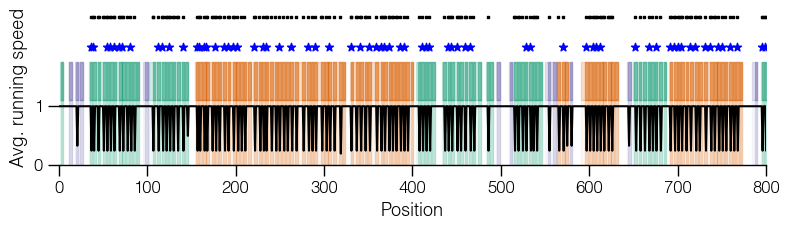

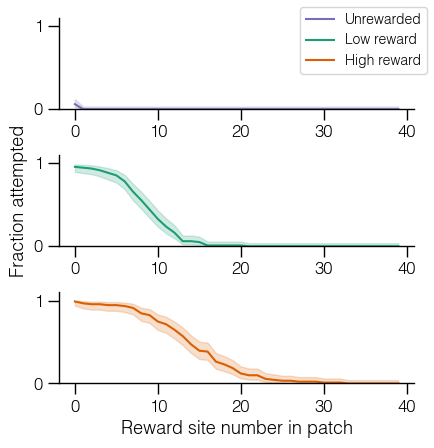

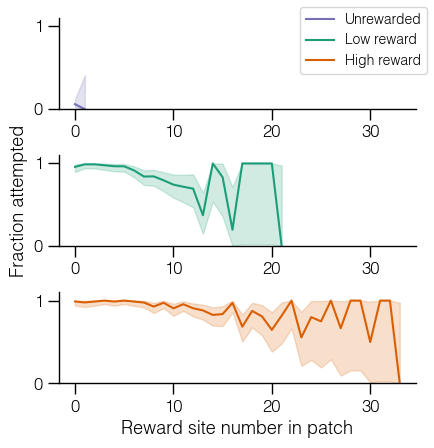

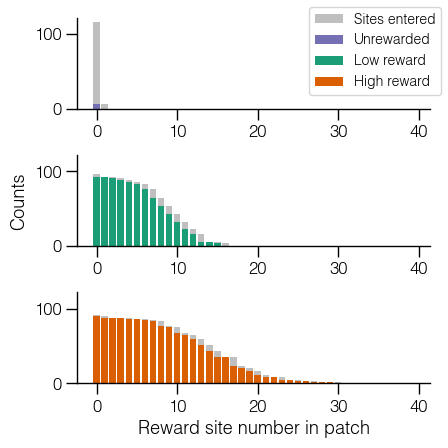

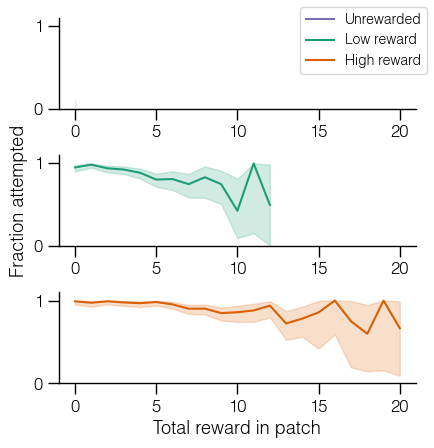

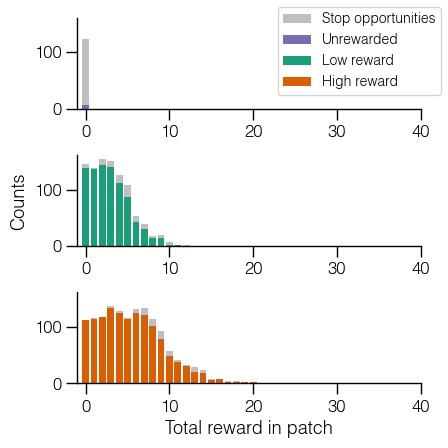

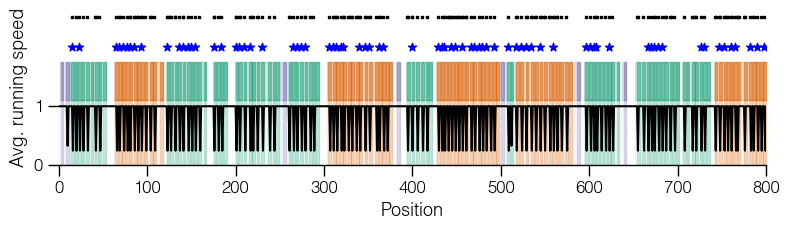

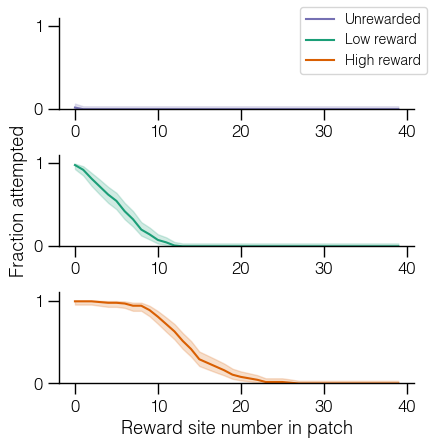

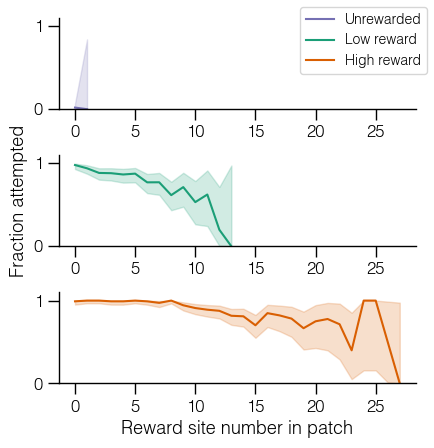

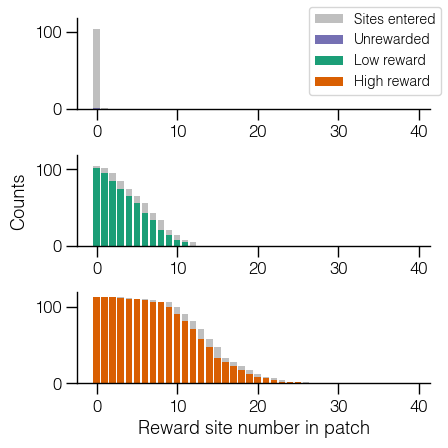

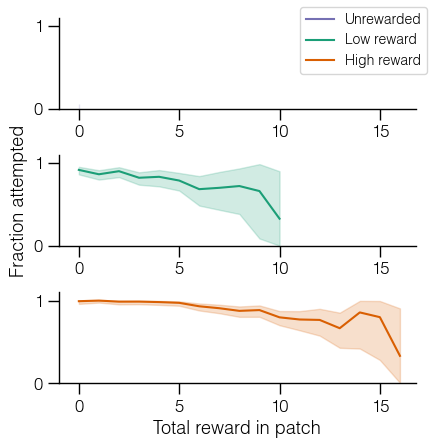

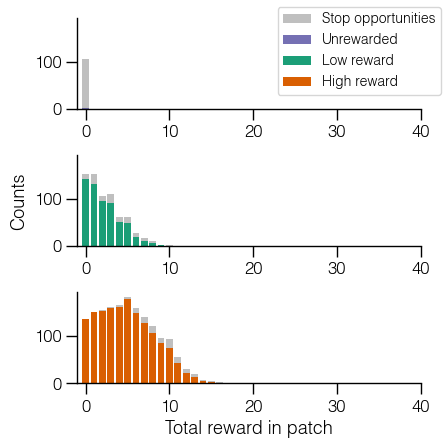

In [10]:
for i, data_path in enumerate(CURRICULUM_TRAINED_NETWORKS):
    plot_session(
        data_path,
        session_idx=0,
        xlim=(0, 800),
        max_reward_param=40,
        max_reward_sites=30,
        use_fixed_colors=True,
        color_by_reward_param=False
    )

[0.  0.6 0.8]
[0.  0.6 0.8]
[0.  0.6 0.8]
[0.  0.6 0.8]


/home/david.bell/work/favorably_connected_2/code/behavioral_plotting.py:158: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(3, 1, figsize=(3 * scale, 3 * scale), sharex=True, sharey=True)


[0.  0.6 0.8]
[0.  0.6 0.8]
[0.  0.6 0.8]
[0.  0.6 0.8]


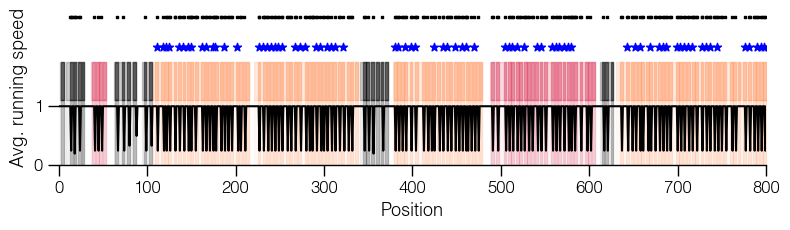

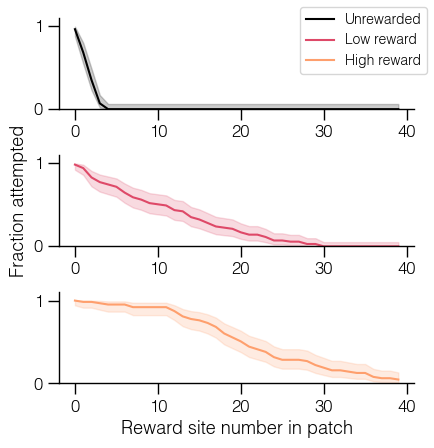

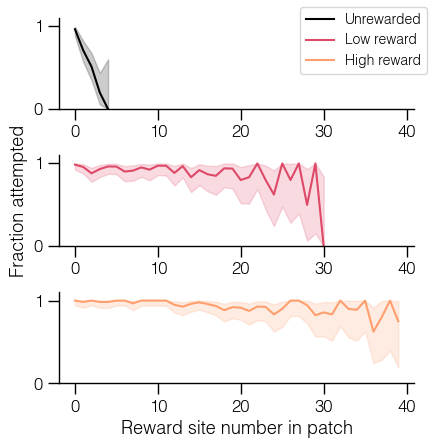

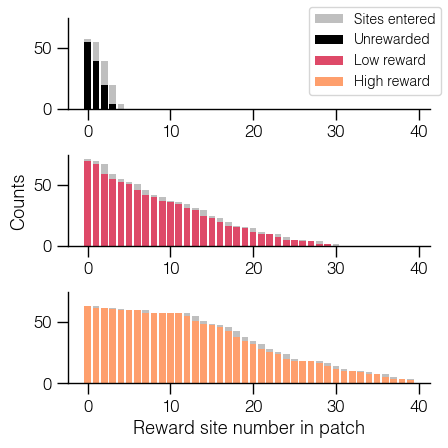

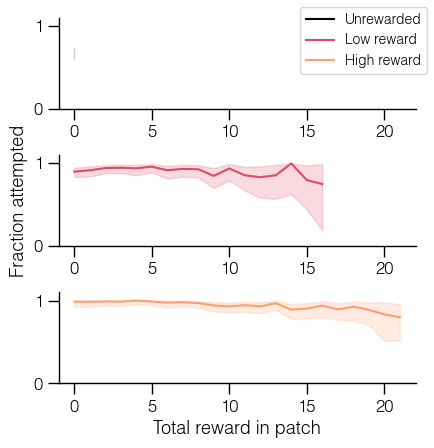

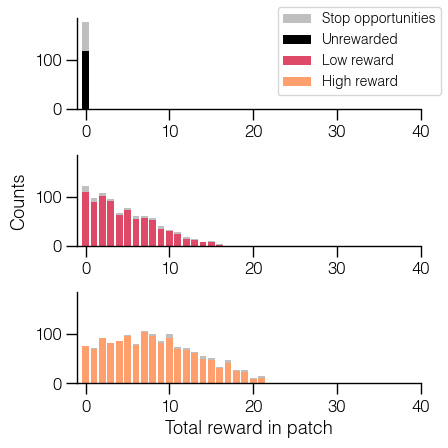

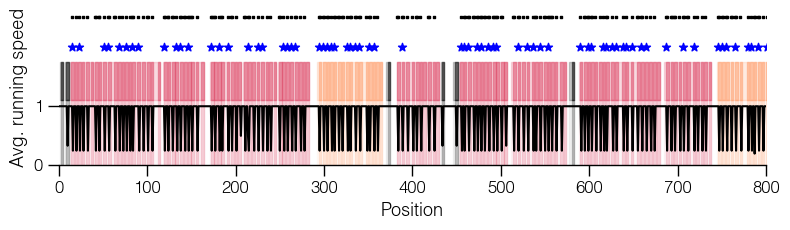

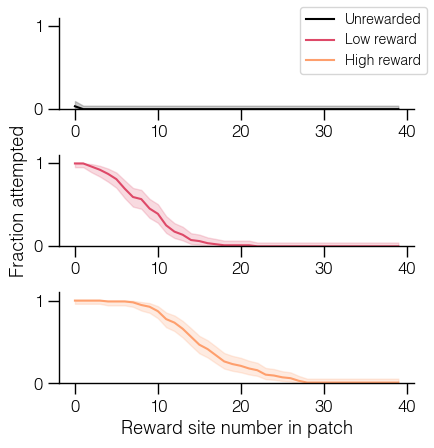

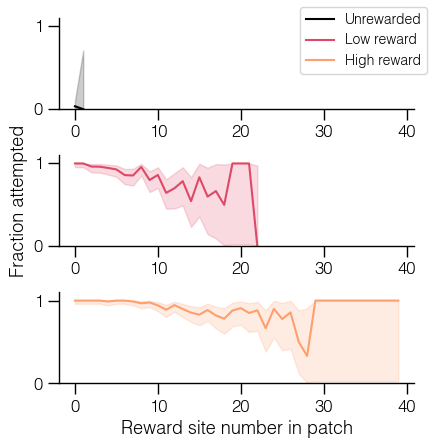

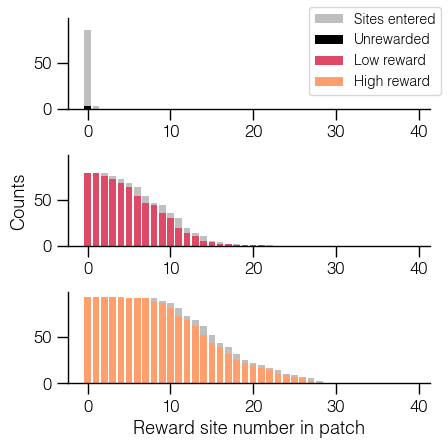

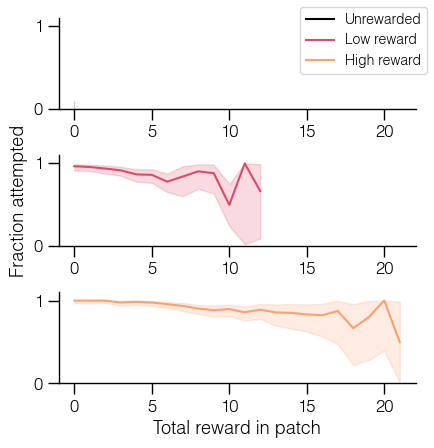

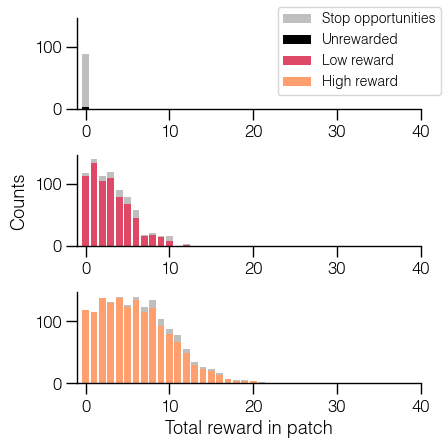

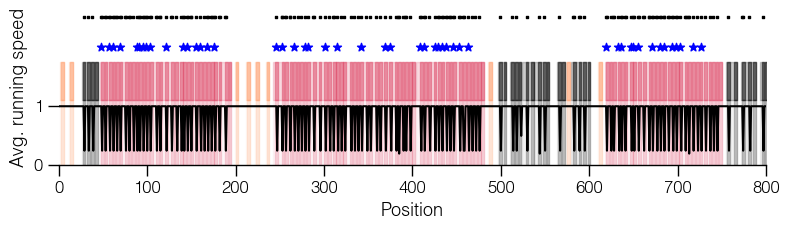

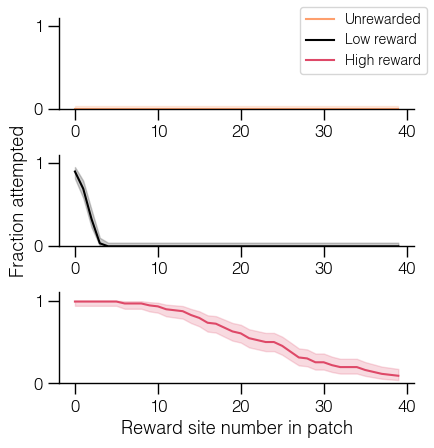

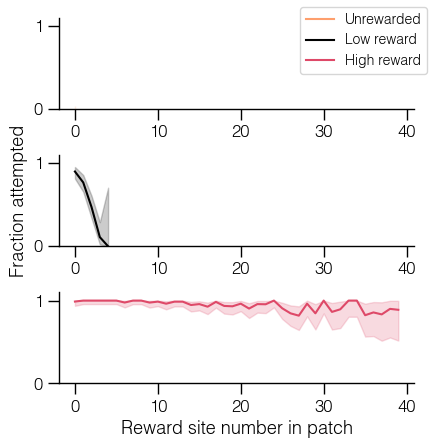

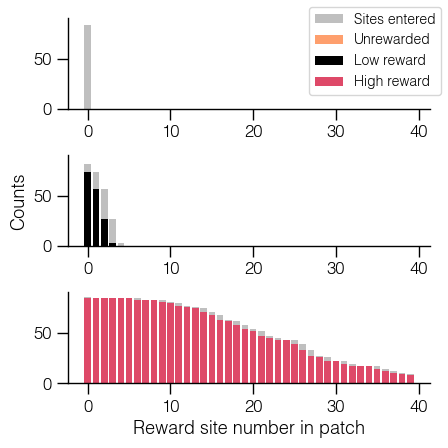

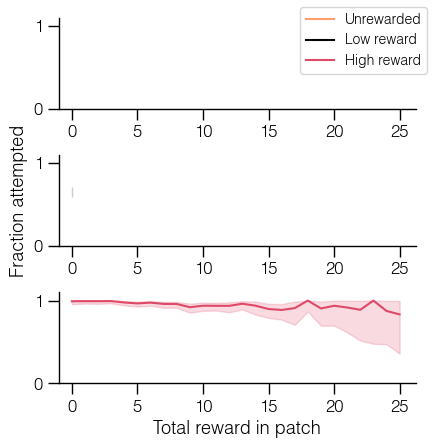

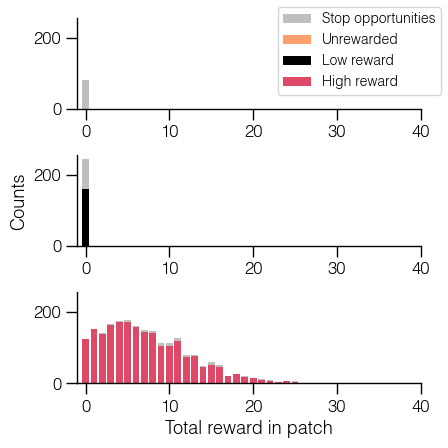

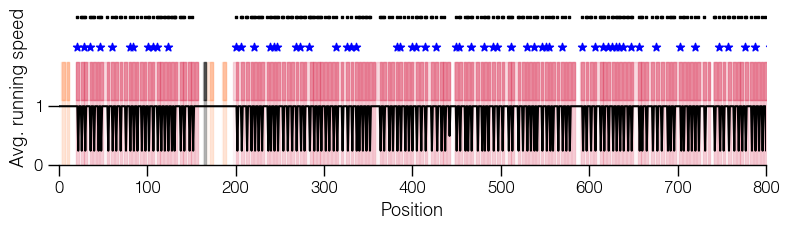

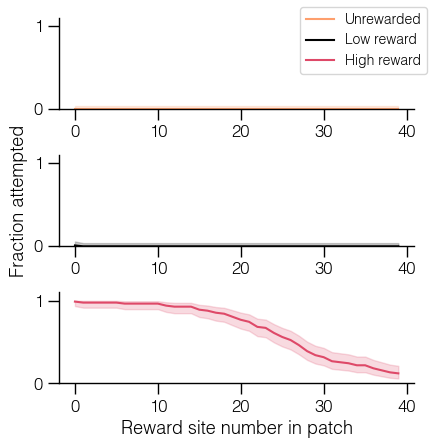

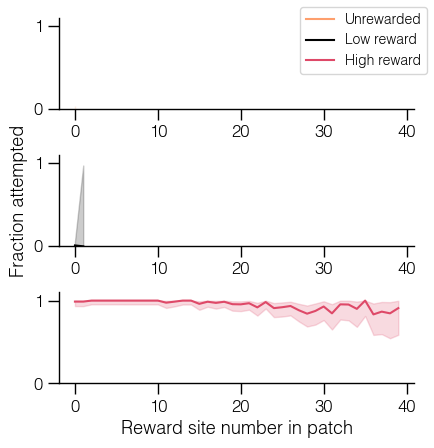

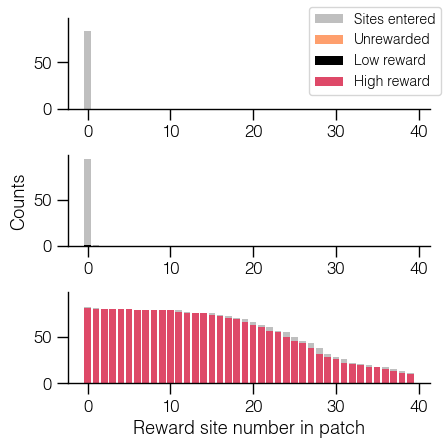

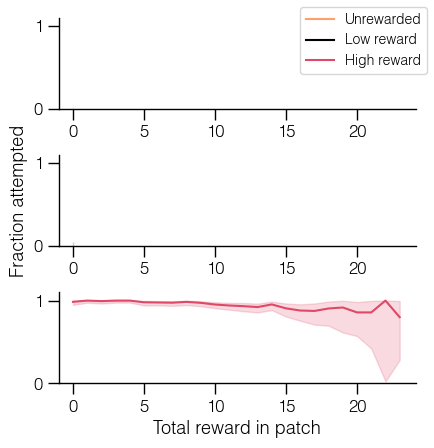

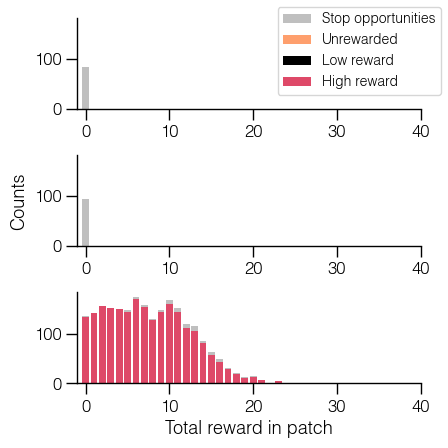

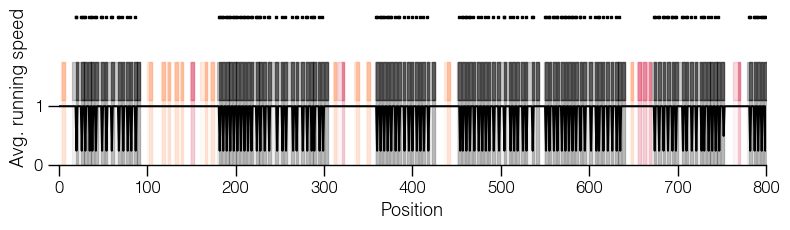

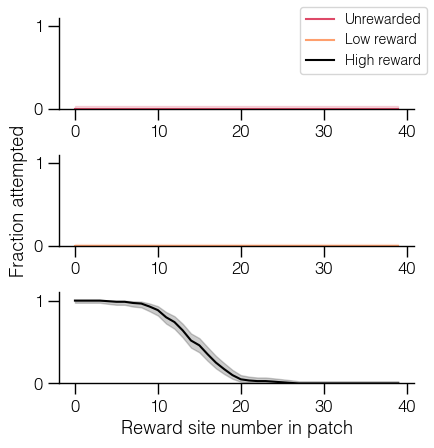

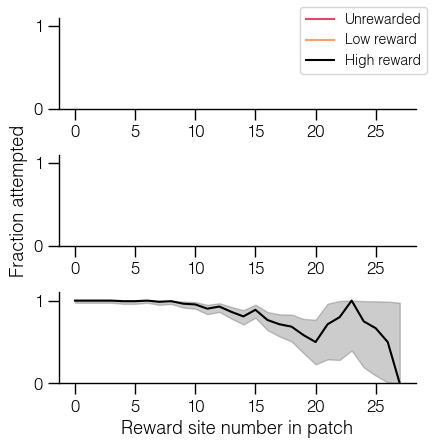

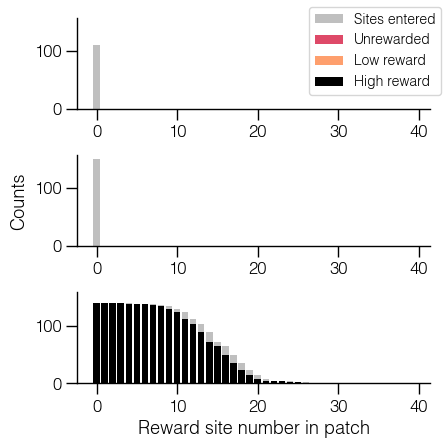

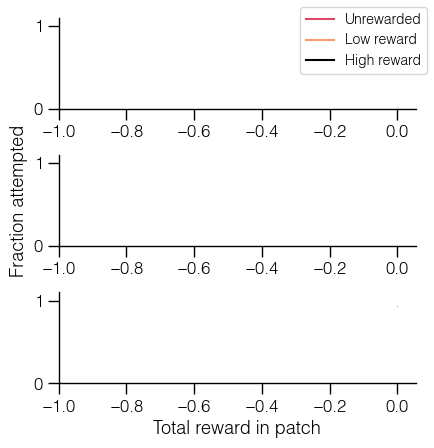

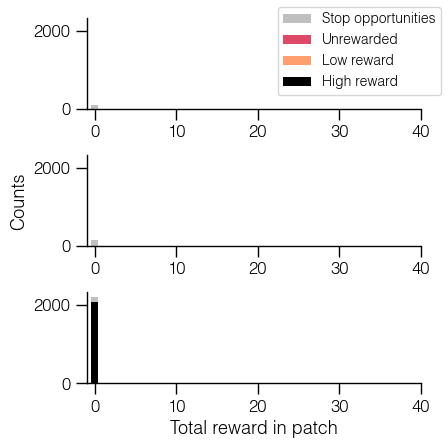

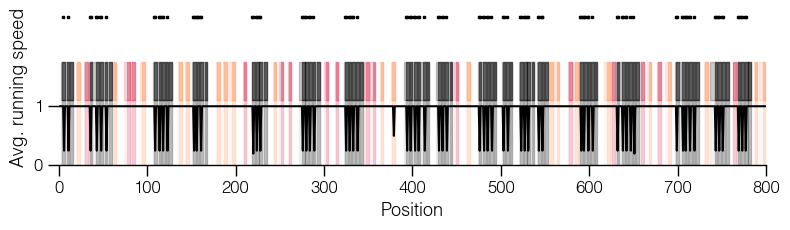

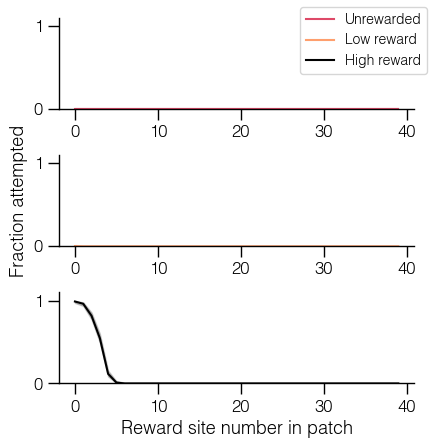

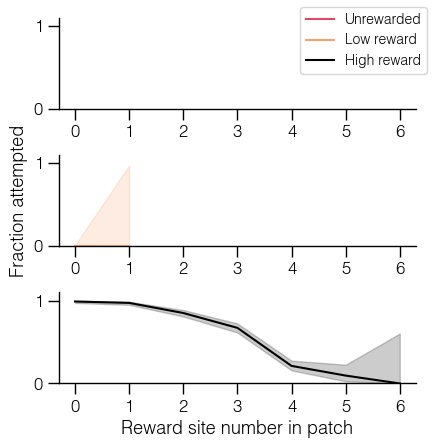

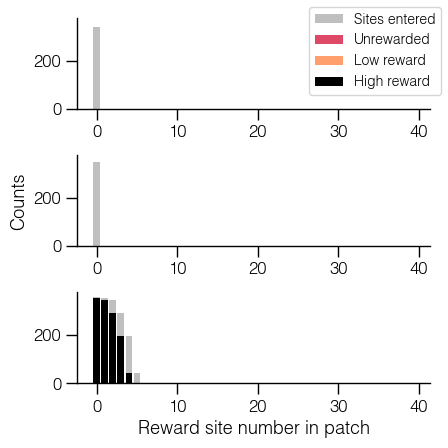

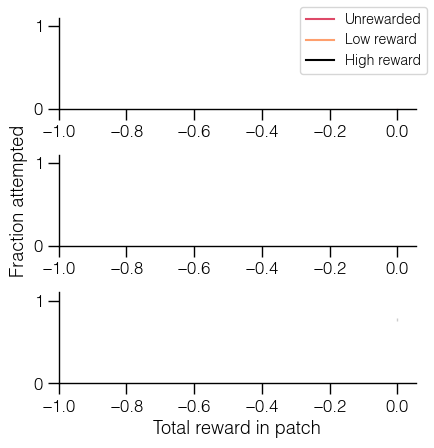

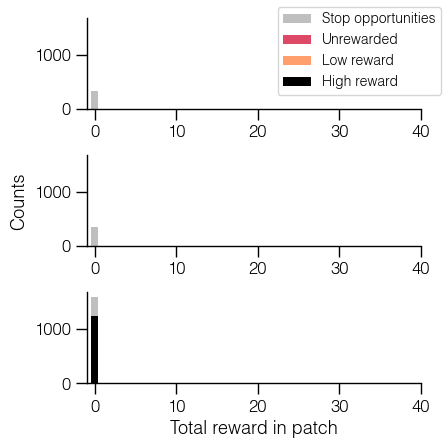

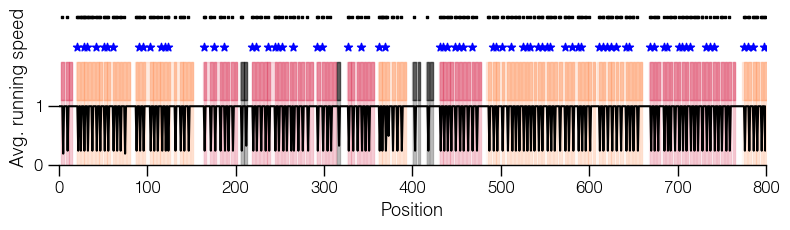

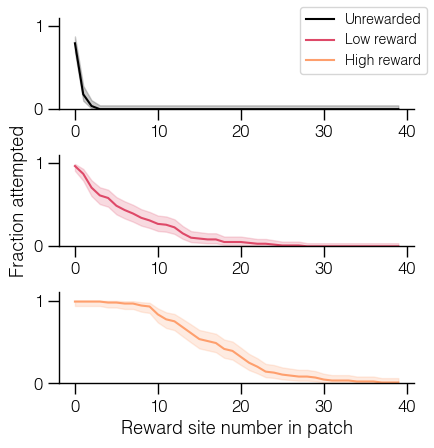

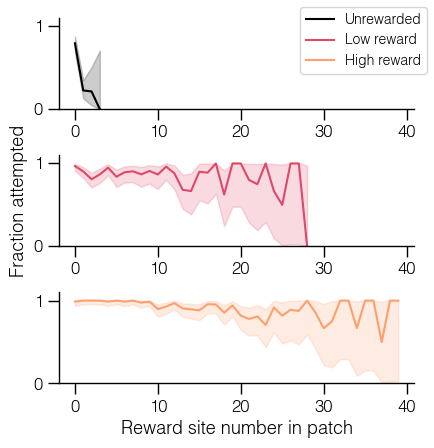

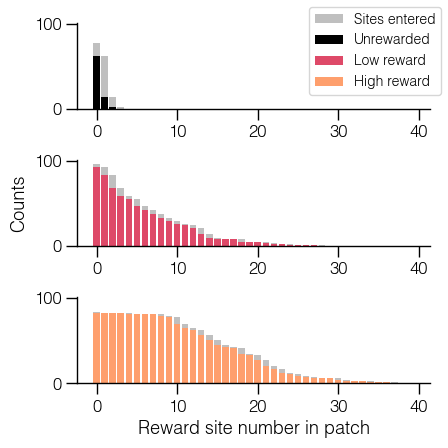

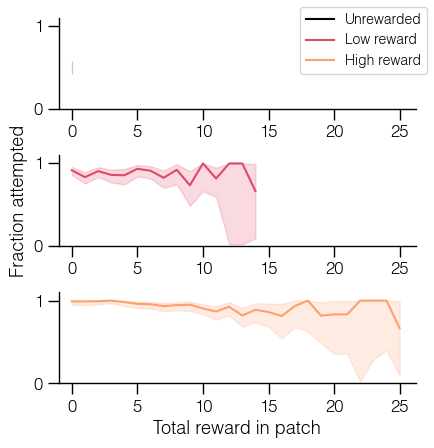

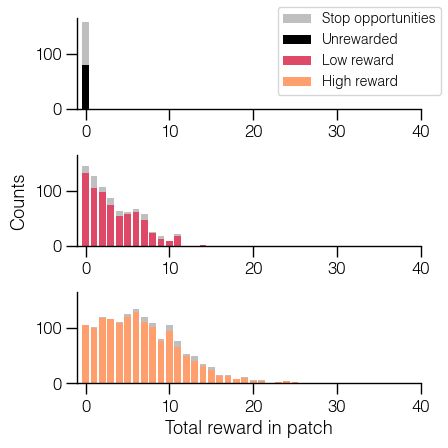

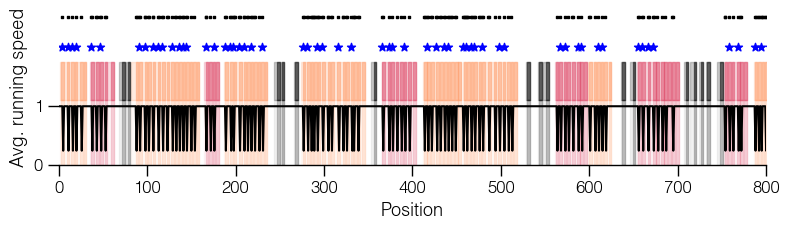

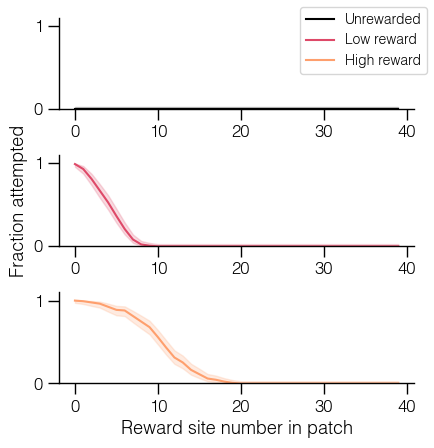

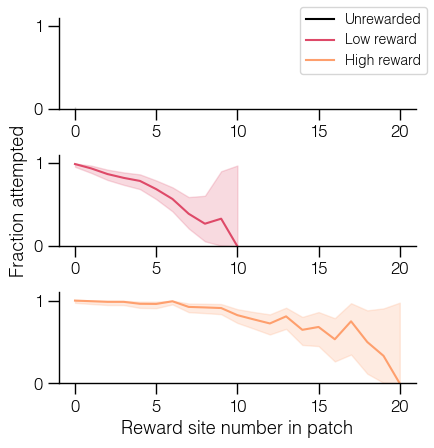

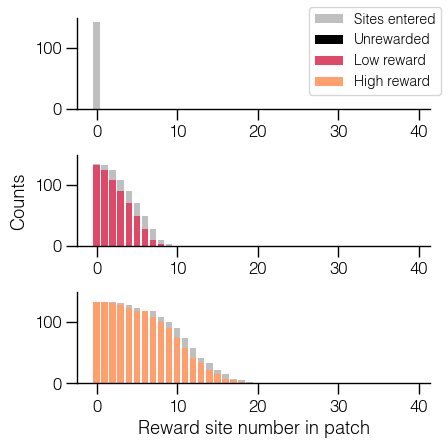

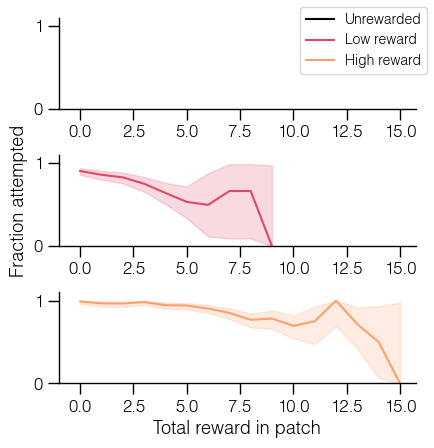

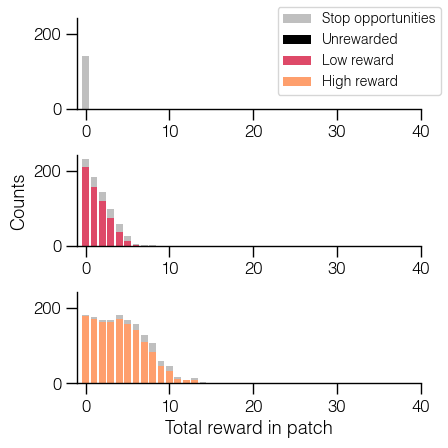

In [15]:
for i, data_path in enumerate(CURRICULUM_TRAINED_NETWORKS_MULTISTAGE_CYCLIC):
    plot_session(
        data_path,
        session_idx=0,
        xlim=(0, 800),
        max_reward_param=40,
        max_reward_sites=30,
        use_fixed_colors=False,
        color_by_reward_param=False
    )

[0.6049904 0.7294496 0.8368939]
[0.14650524 0.31496397 0.5855848 ]
[0.04743373 0.08903795 0.14716926]
[0.63981736 0.6796112  0.74762154]


/home/david.bell/work/favorably_connected_2/code/behavioral_plotting.py:158: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(3, 1, figsize=(3 * scale, 3 * scale), sharex=True, sharey=True)


[0.54287076 0.824695   0.8510723 ]


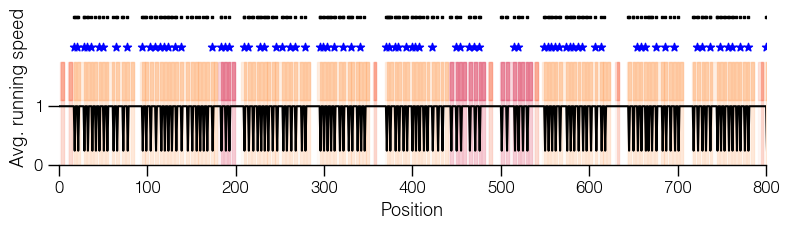

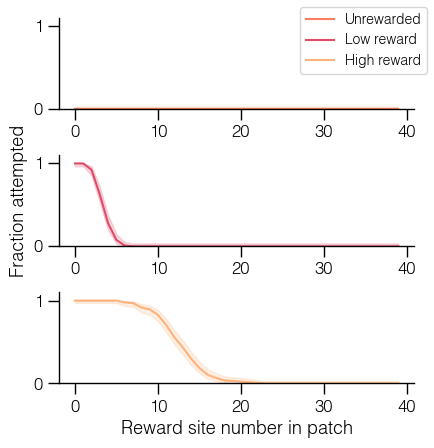

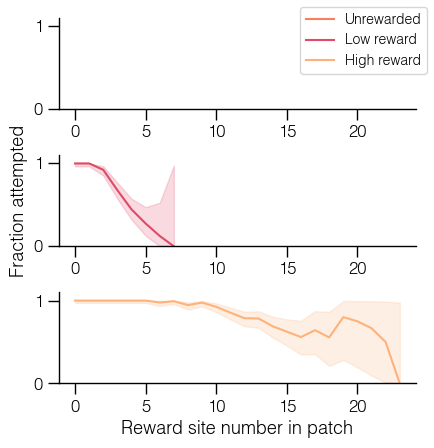

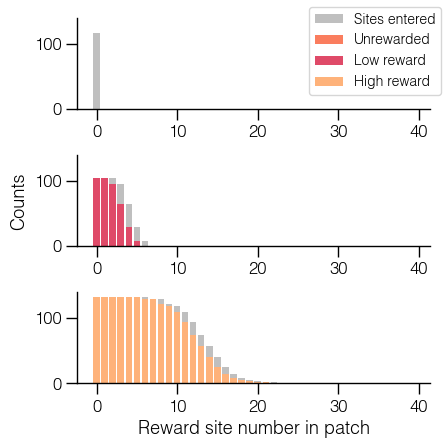

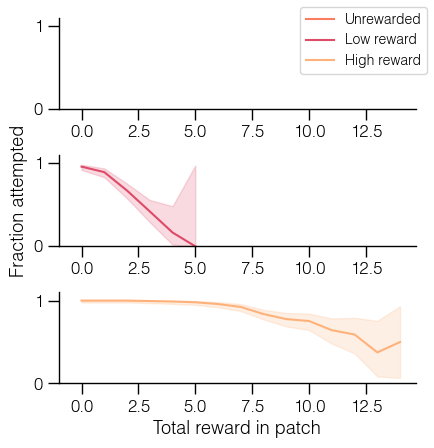

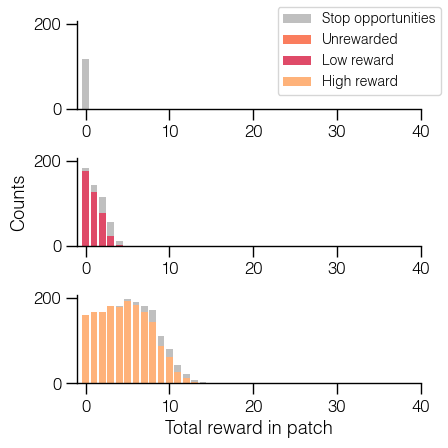

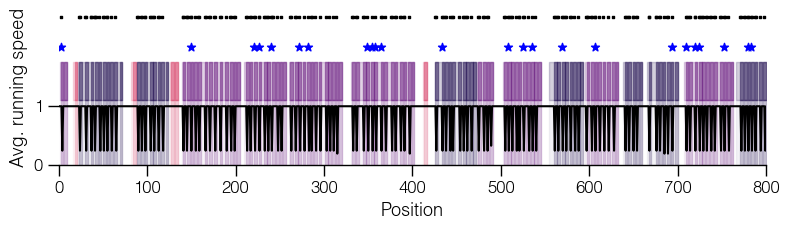

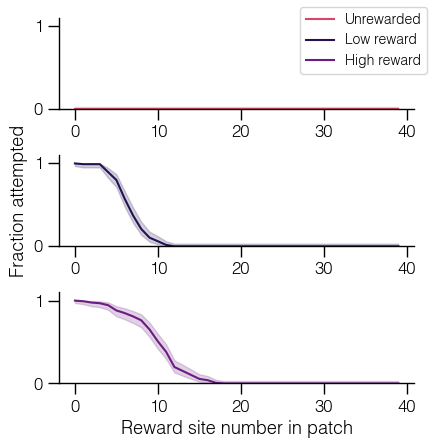

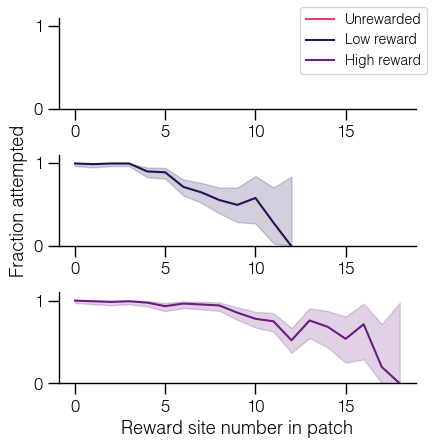

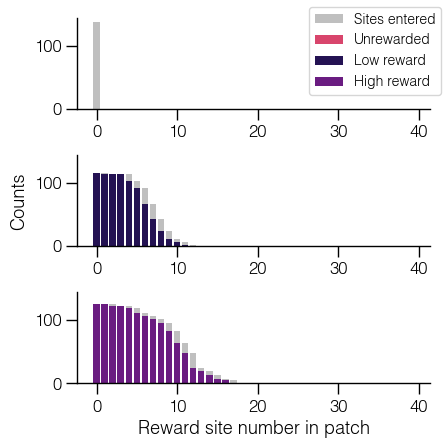

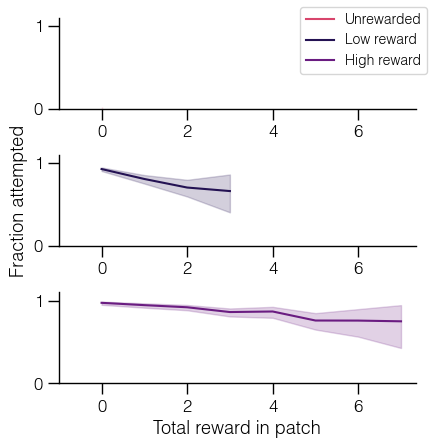

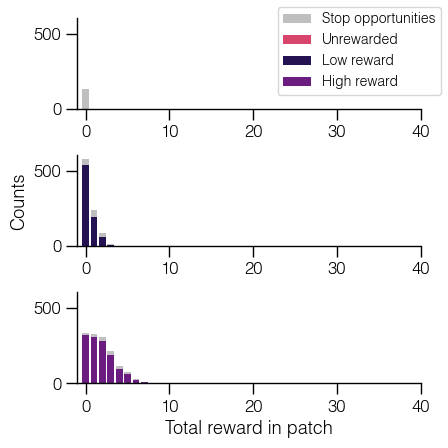

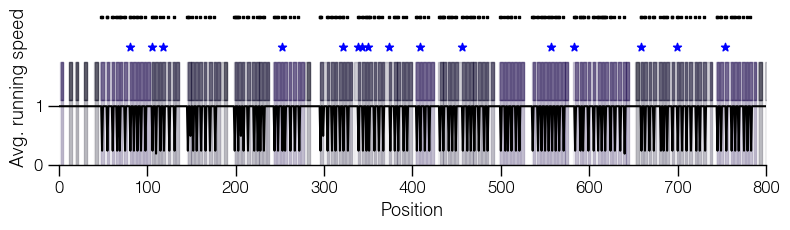

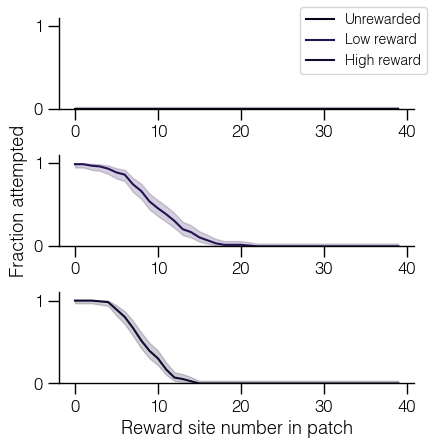

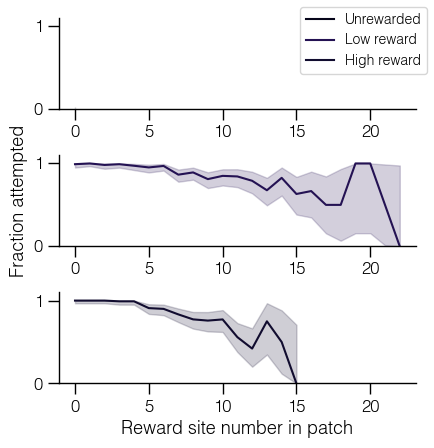

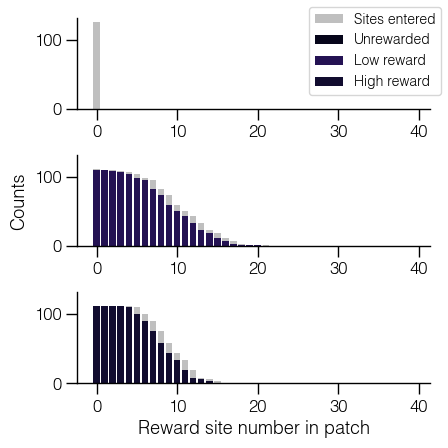

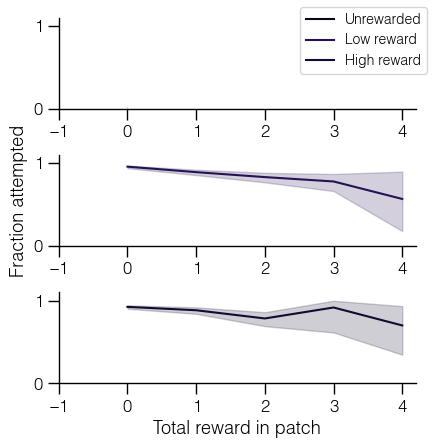

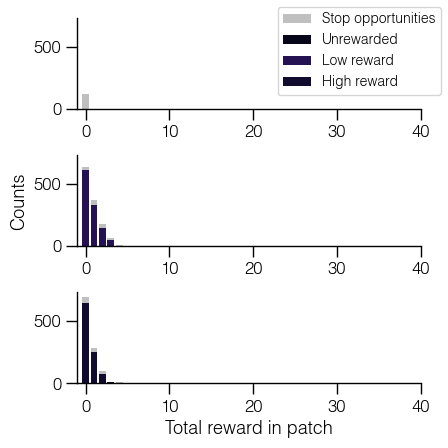

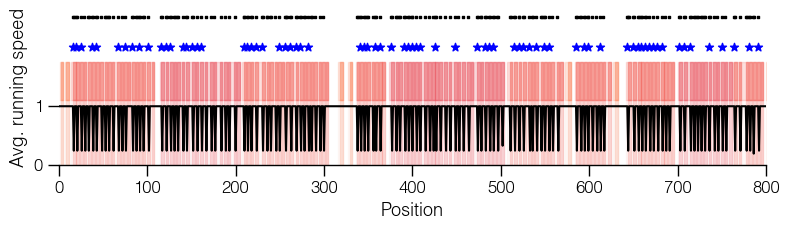

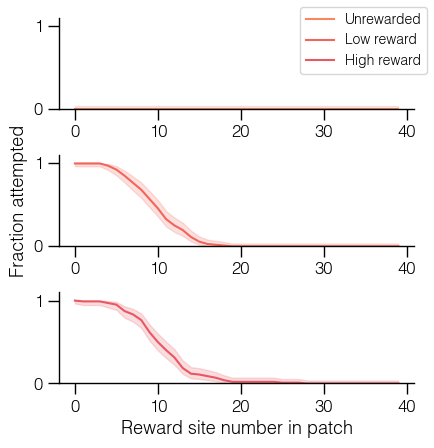

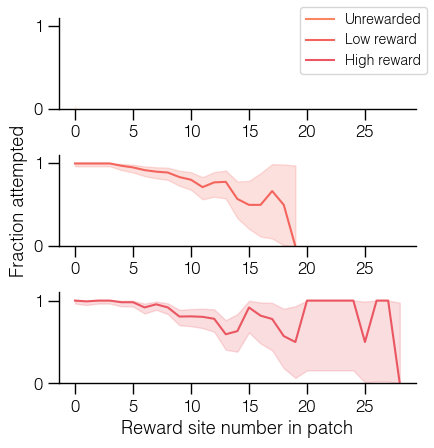

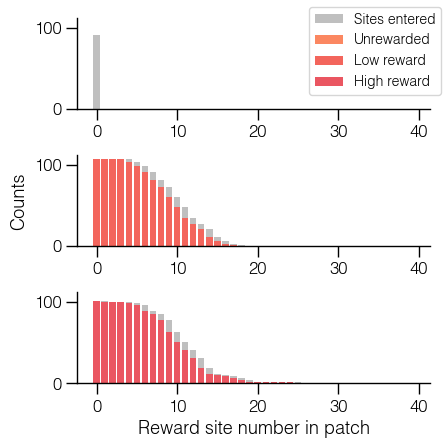

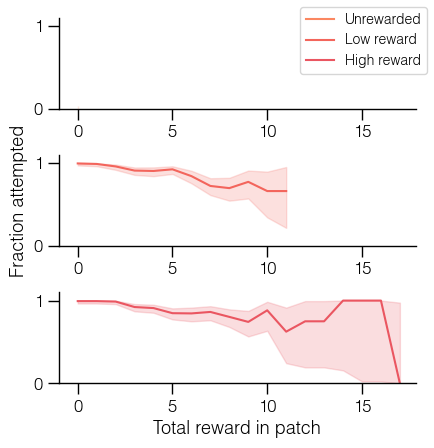

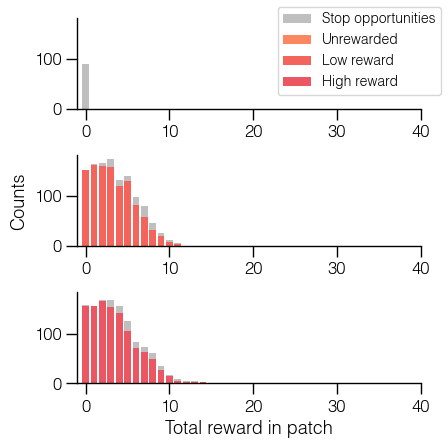

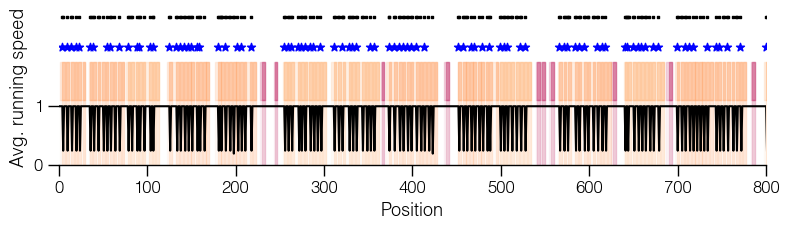

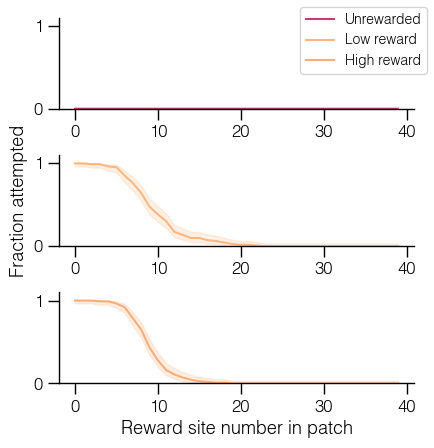

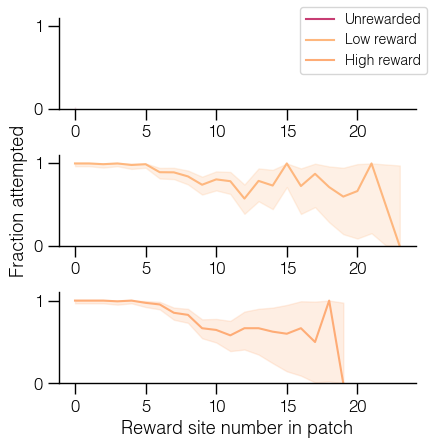

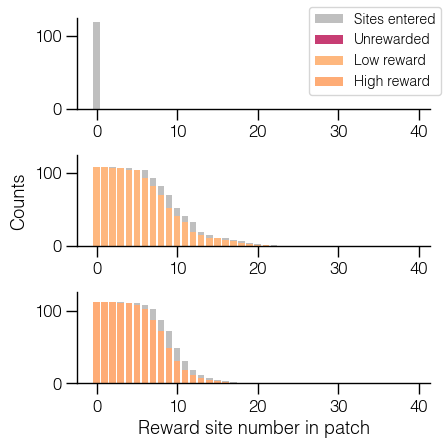

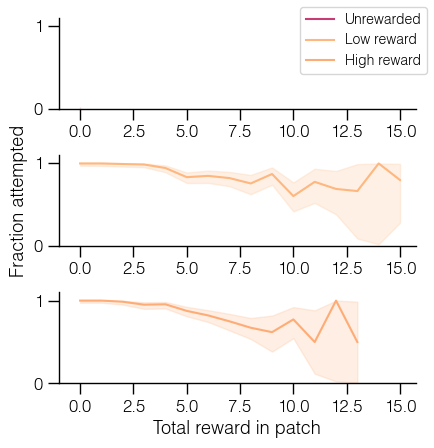

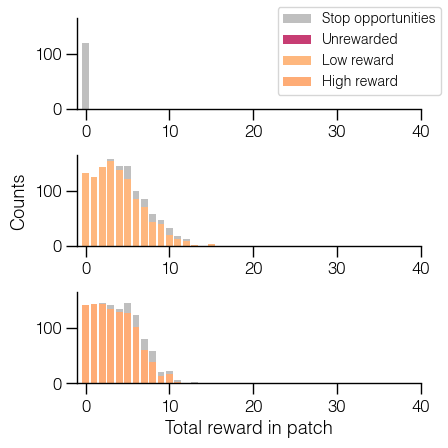

In [21]:
for i, data_path in enumerate(CURRICULUM_TRAINED_NETWORKS_FIXED_TO_COUPLED):
    plot_session(
        data_path,
        session_idx=0,
        xlim=(0, 800),
        max_reward_param=40,
        max_reward_sites=30,
        use_fixed_colors=False,
        color_by_reward_param=False
    )

## Odor site data loading

In [11]:
dfs = [
    load_odor_site_df(x, nn_num=nn_num)
    for nn_num, x in enumerate(CURRICULUM_TRAINED_NETWORKS)
]

Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated


In [16]:
dfs_multistage_cycle = [
    load_odor_site_df(x, nn_num=nn_num)
    for nn_num, x in enumerate(CURRICULUM_TRAINED_NETWORKS_MULTISTAGE_CYCLIC)
]

Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated


In [22]:
dfs_fixed_to_coupled = [
    load_odor_site_df(x, nn_num=nn_num)
    for nn_num, x in enumerate(CURRICULUM_TRAINED_NETWORKS_FIXED_TO_COUPLED)
]

Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated


In [35]:
dfs_fixed_to_equal_low = [
    load_odor_site_df(x, nn_num=nn_num)
    for nn_num, x in enumerate(CURRICULUM_TRAINED_NETWORKS_FIXED_TO_EQUAL_LOW)
]

Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries ge

In [77]:
dfs_fixed_to_equal_high = [
    load_odor_site_df(x, nn_num=nn_num)
    for nn_num, x in enumerate(CURRICULUM_TRAINED_NETWORKS_FIXED_TO_EQUAL_HIGH)
]

Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated


<string>:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<string>:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<string>:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
<string>:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, 

Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated


In [76]:
dfs_coupled_to_fixed_v2 = [
    load_odor_site_df(x, nn_num=nn_num)
    for nn_num, x in enumerate(CURRICULUM_TRAINED_NETWORKS_V2)
]

Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated
Session data loaded
Session summaries generated


## Mean rewards harvested and probability of reward at leave across sessions

### Global reward rate estimating network

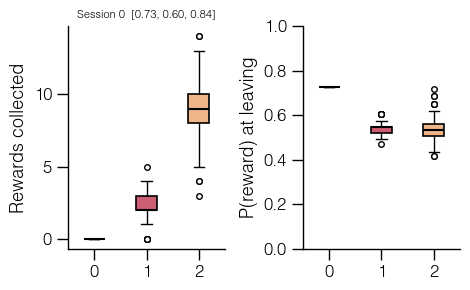

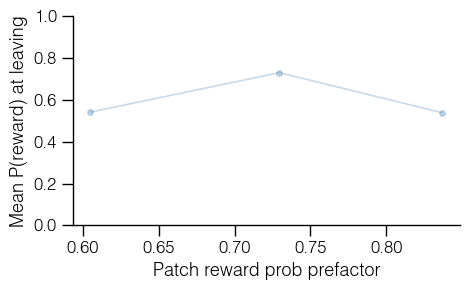

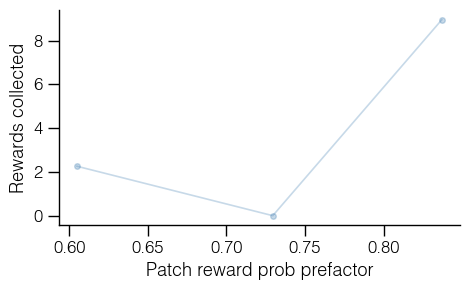

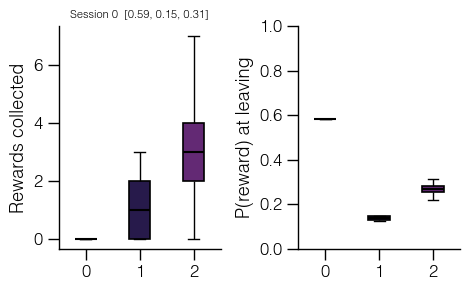

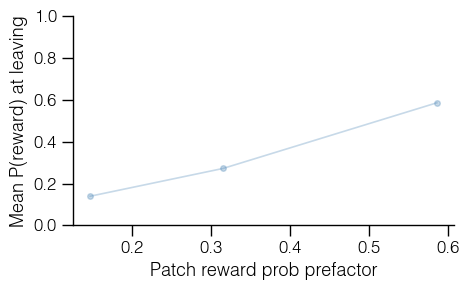

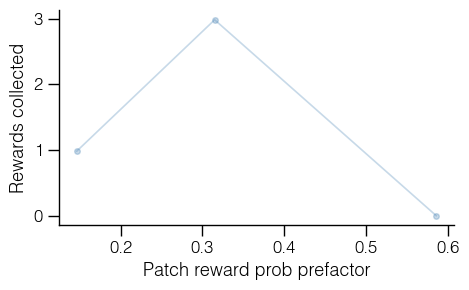

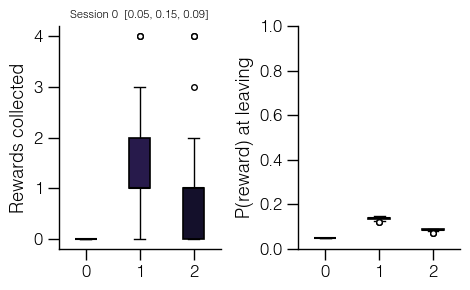

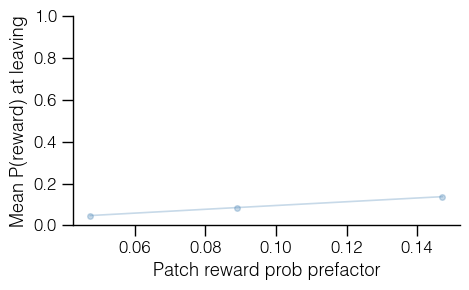

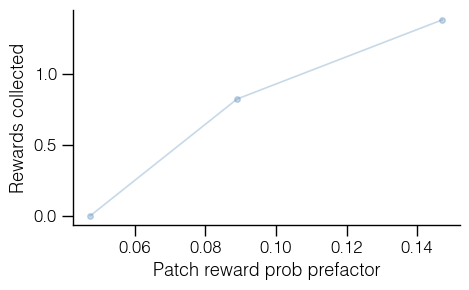

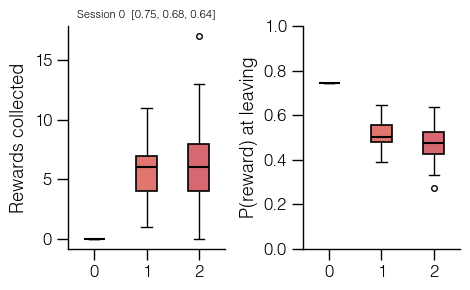

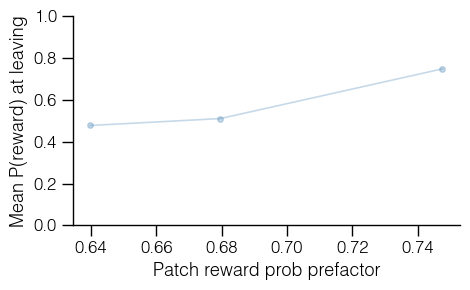

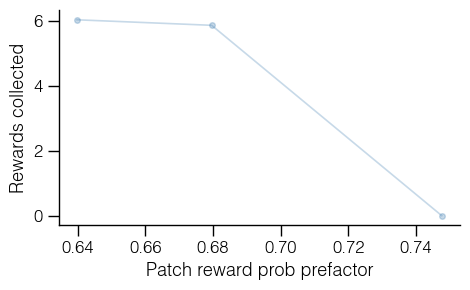

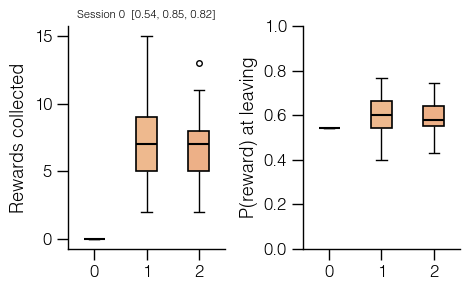

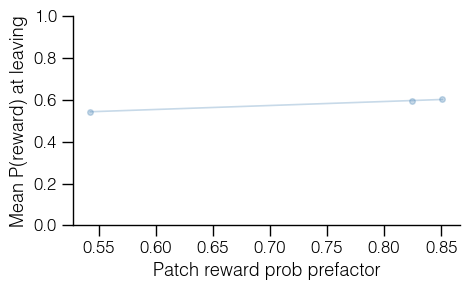

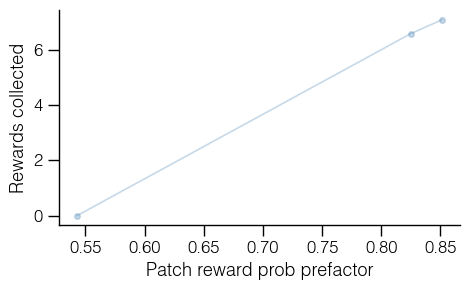

In [23]:
for df in dfs_fixed_to_coupled:
    plot_patch_statistics_per_session(
        df,
        ylim_right=[0, 1.],
    )

/home/david.bell/work/favorably_connected_2/code/behavioral_plotting.py:510: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig_summary_rewards, ax_rew = plt.subplots(figsize=(n_types * 1.2 + 1.2, 3))


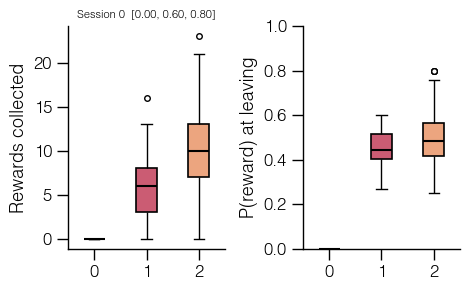

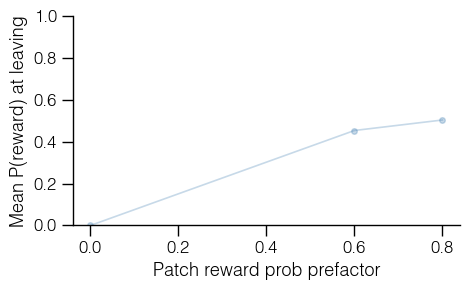

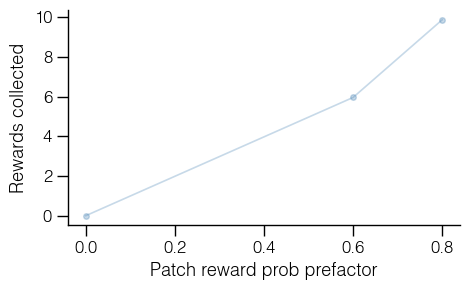

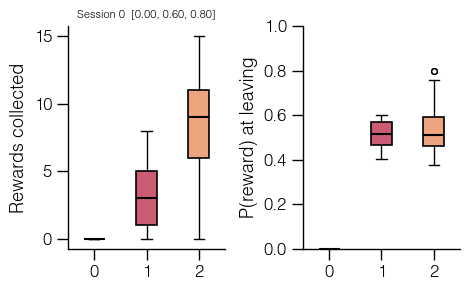

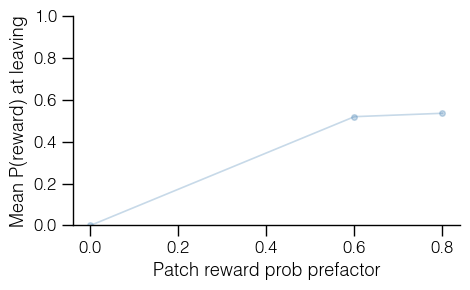

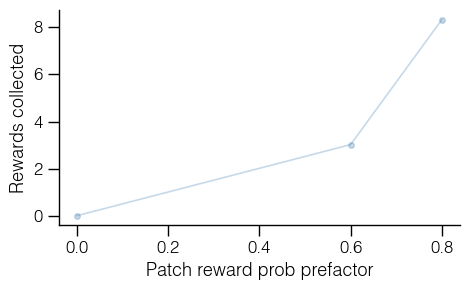

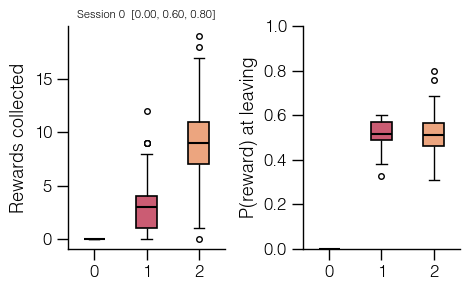

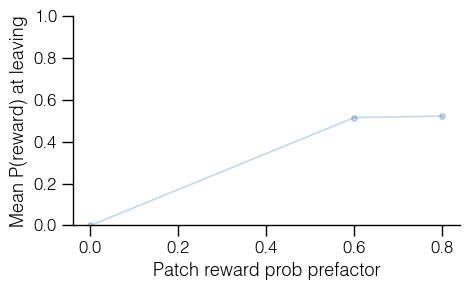

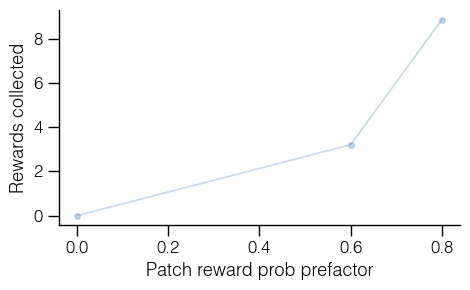

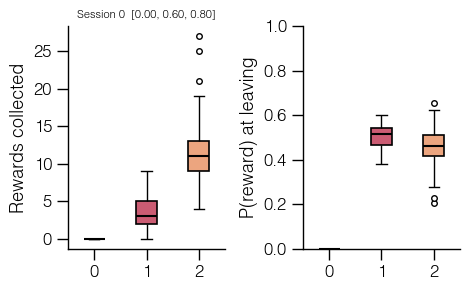

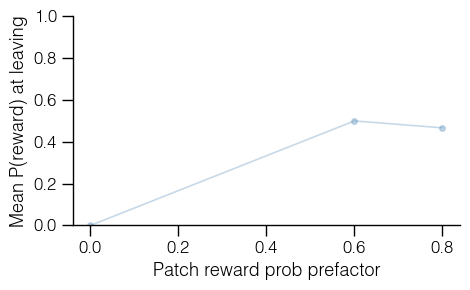

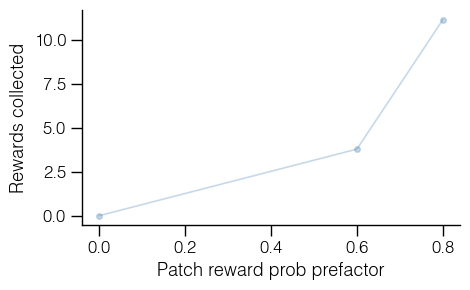

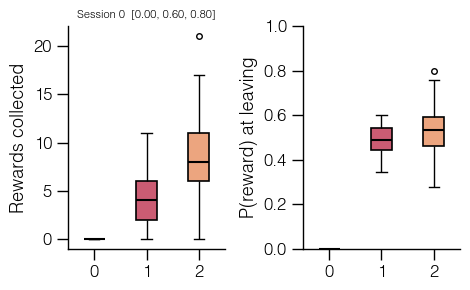

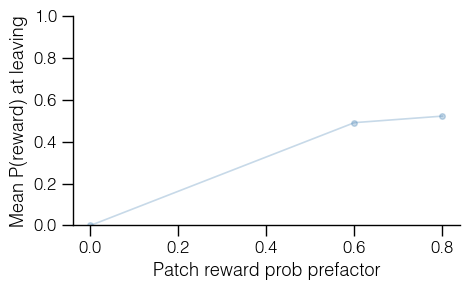

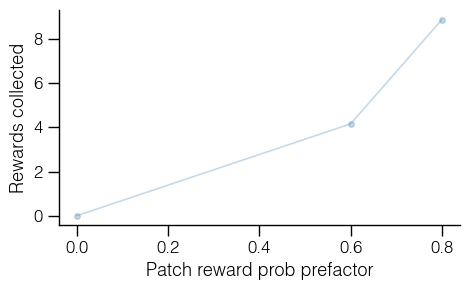

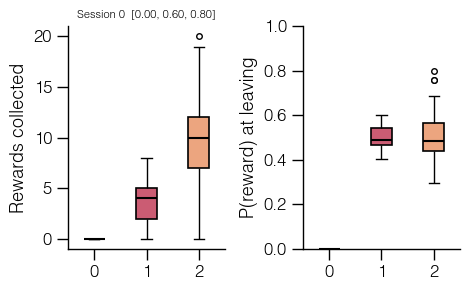

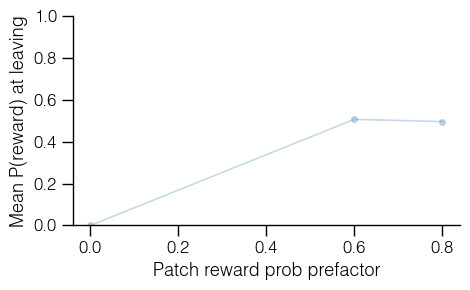

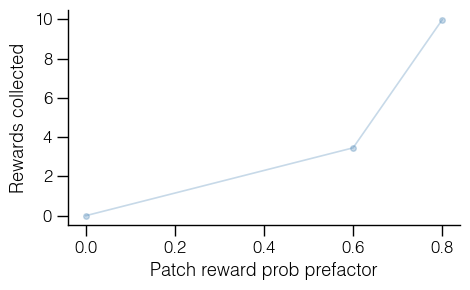

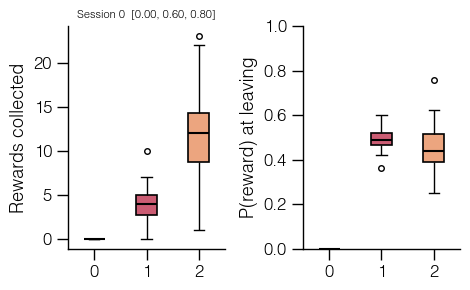

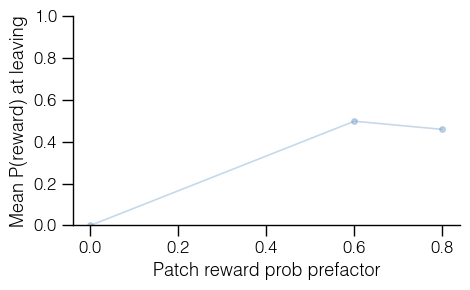

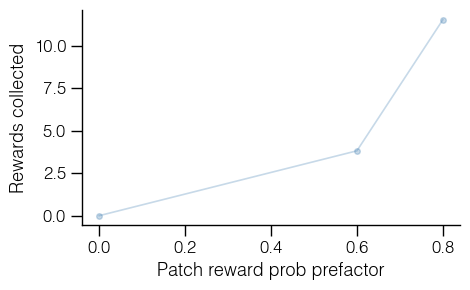

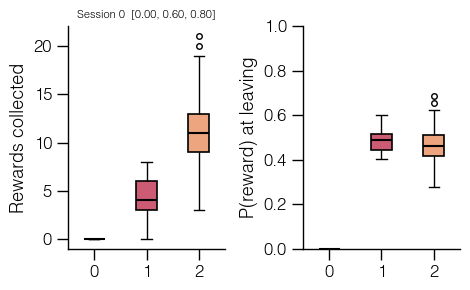

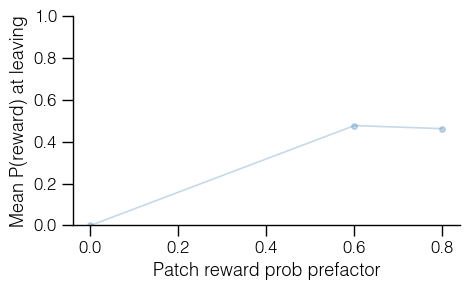

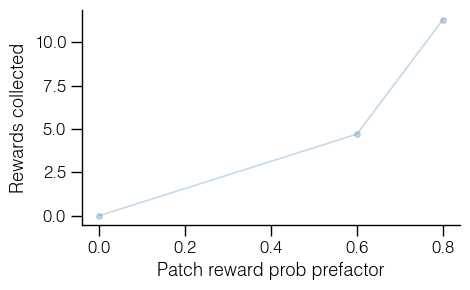

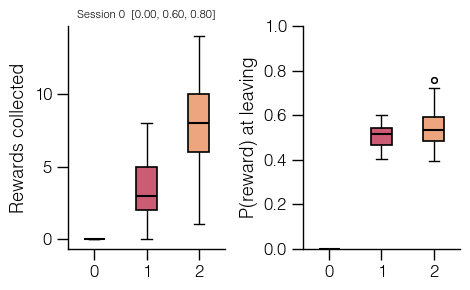

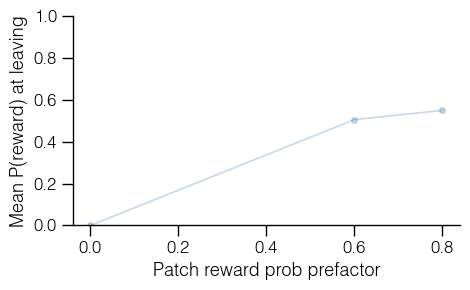

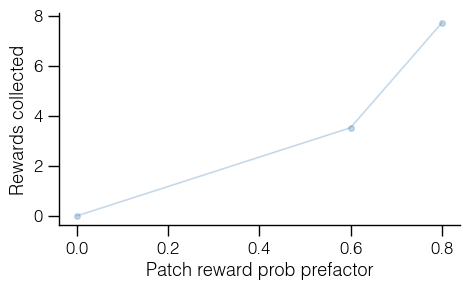

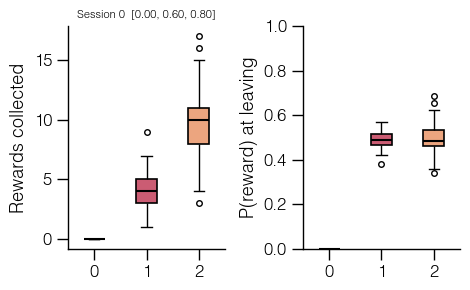

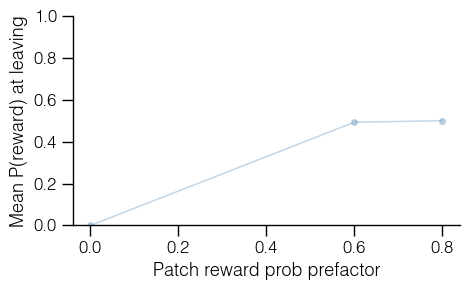

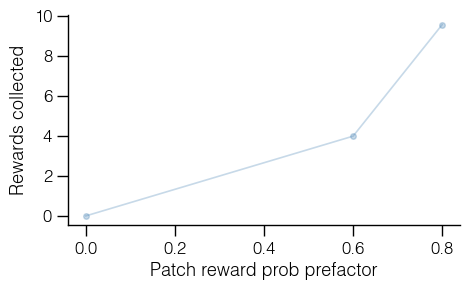

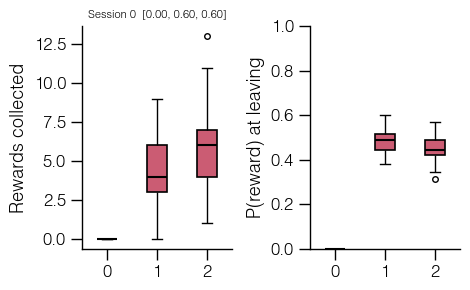

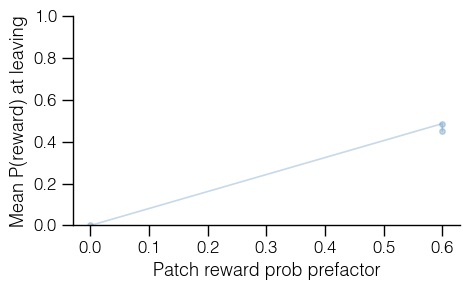

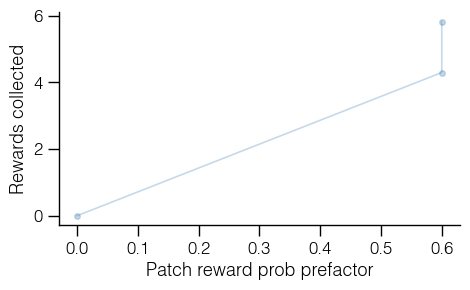

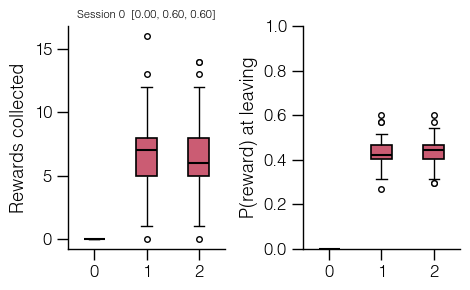

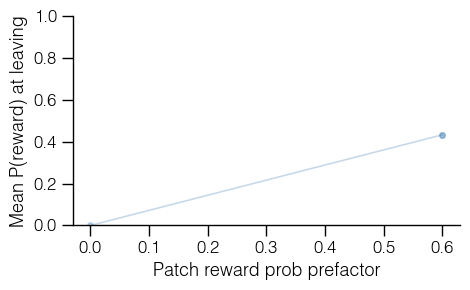

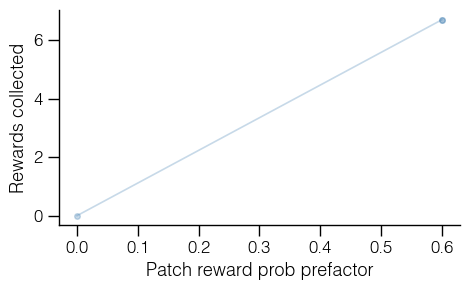

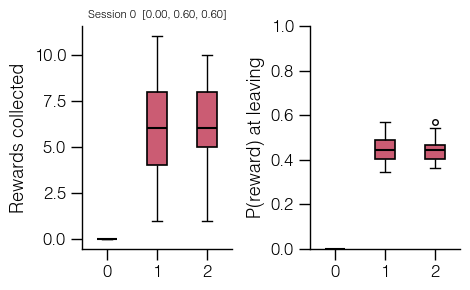

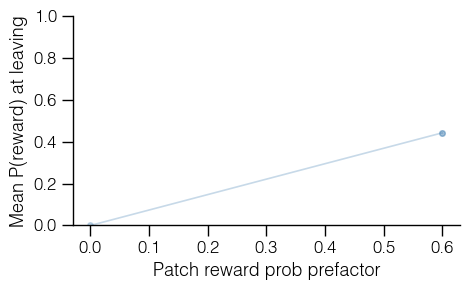

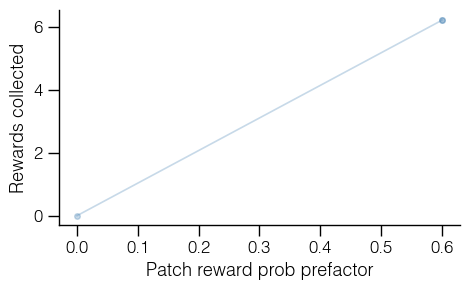

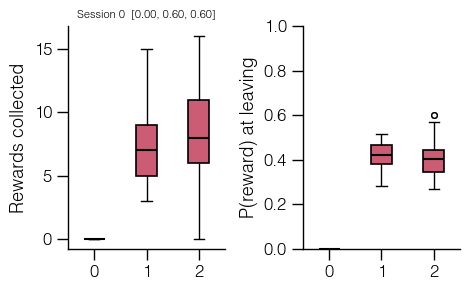

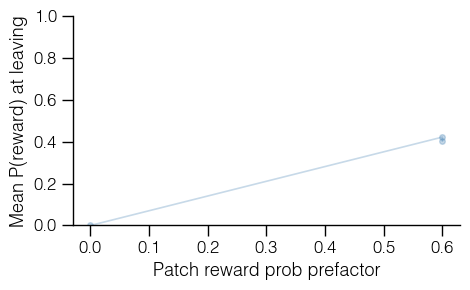

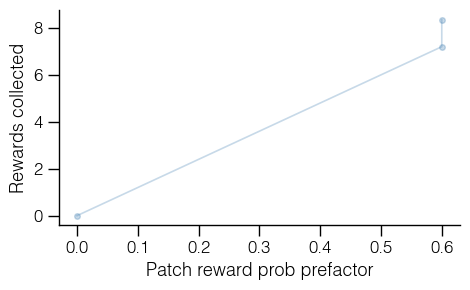

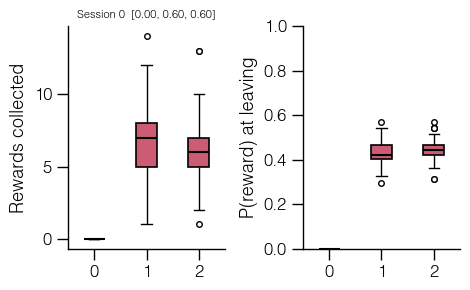

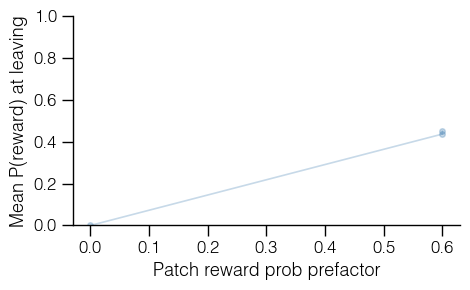

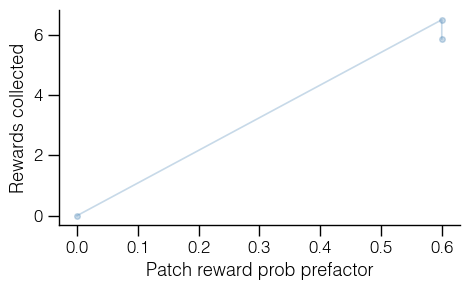

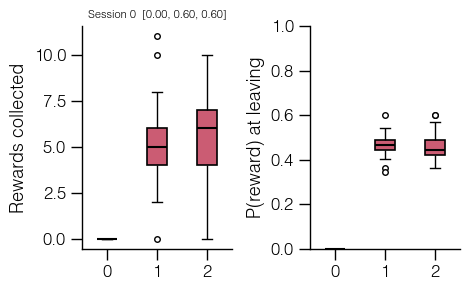

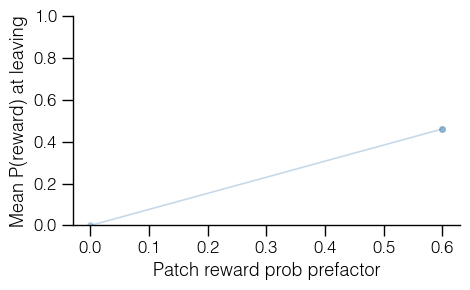

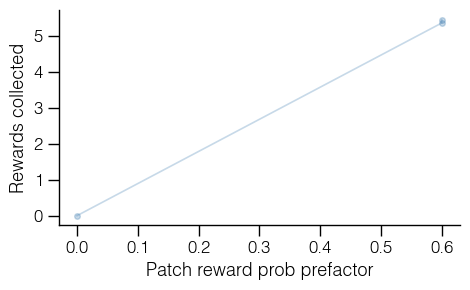

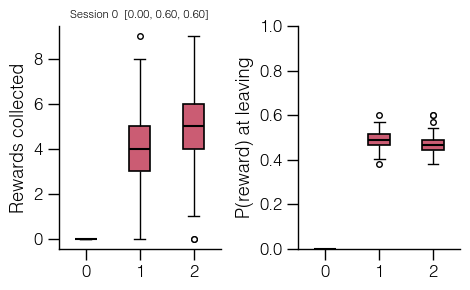

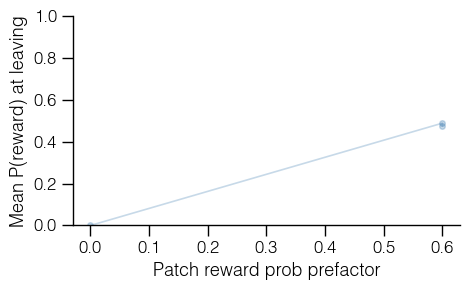

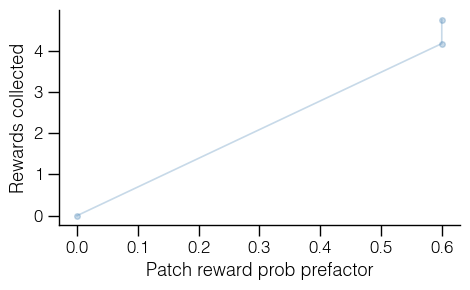

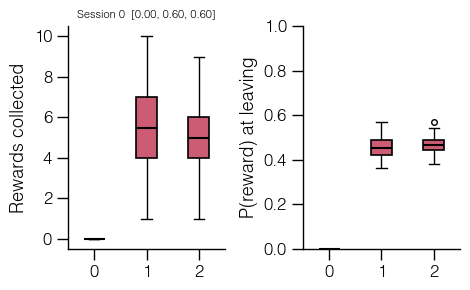

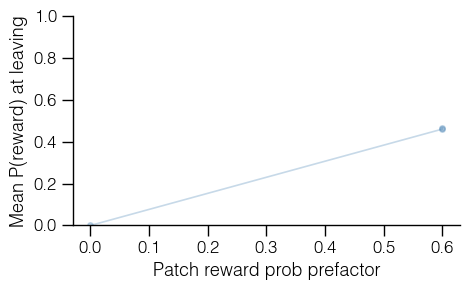

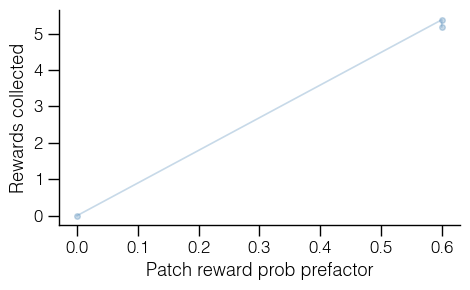

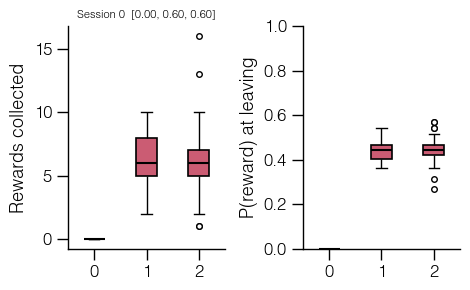

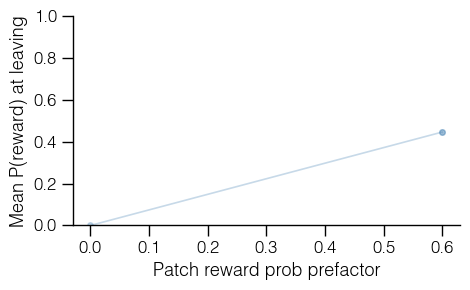

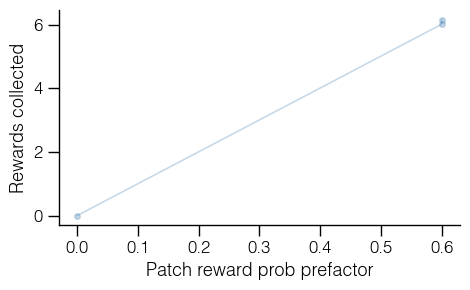

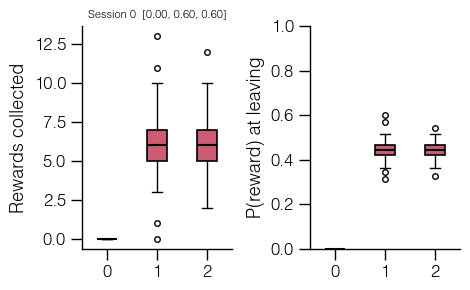

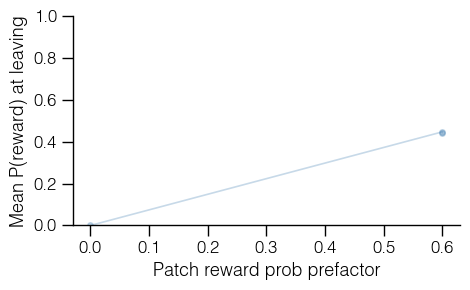

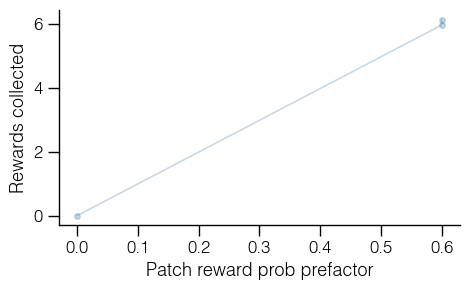

In [ ]:
for df in dfs_fixed_to_equal_low:
    plot_patch_statistics_per_session(
        df,
        ylim_right=[0, 1.],
        
        
    )

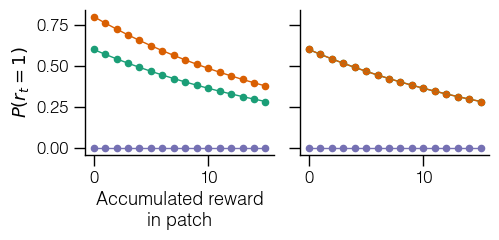

In [73]:
fig, axes = plt.subplots(1, 2, figsize=(5, 2.5), sharex=True, sharey=True)

x = np.arange(16)   # 0 through 20

# ── Exponential decay curves ──────────────────────────────────────────────
prefactors  = [0,  0.6,  0.8]   # one per curve
decay_rates = [1,  1/20,  1/20]   # one per curve

for (prefactor, decay_rate, color) in zip(prefactors, decay_rates, odor_colors):
    y = prefactor * np.exp(-decay_rate * x)
    axes[0].plot(x, y, color=color, lw=1)
    axes[0].scatter(x, y, color=color, s=20)
axes[0].set_xlabel('Accumulated reward\nin patch')
axes[0].set_ylabel(r'$P(r_t=1)$')

# ── Exponential decay curves ──────────────────────────────────────────────
prefactors  = [0,  0.6,  0.6]   # one per curve
decay_rates = [1,  1/20,  1/20]   # one per curve

for (prefactor, decay_rate, color) in zip(prefactors, decay_rates, odor_colors):
    y = prefactor * np.exp(-decay_rate * x)
    axes[1].plot(x, y, color=color, lw=1)
    axes[1].scatter(x, y, color=color, s=20)


format_plot(axes)
plt.tight_layout()
plt.show()

In [ ]:
fig1, ax1, fig2, ax2, fig3, ax3 = plot_patch_statistics_across_dfs(
    dfs_fixed_to_equal_low[1:],
    xticks=np.arange(5) * 5,
    xticklabels=[f'{s}' for s in np.arange(500, 701, 50)],
)
for ax in [ax1, ax2, ax3]:
    ax.axvline(10, color='grey', ls='--')
plt.show(fig1)
plt.close(fig1)
plt.show(fig2)
plt.close(fig2)
plt.show(fig3)
plt.close(fig3)

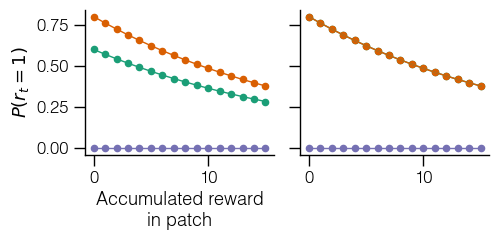

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(5, 2.5), sharex=True, sharey=True)

x = np.arange(16)   # 0 through 20

# ── Exponential decay curves ──────────────────────────────────────────────
prefactors  = [0,  0.6,  0.8]   # one per curve
decay_rates = [1,  1/20,  1/20]   # one per curve

for (prefactor, decay_rate, color) in zip(prefactors, decay_rates, odor_colors):
    y = prefactor * np.exp(-decay_rate * x)
    axes[0].plot(x, y, color=color, lw=1)
    axes[0].scatter(x, y, color=color, s=20)
axes[0].set_xlabel('Accumulated reward\nin patch')
axes[0].set_ylabel(r'$P(r_t=1)$')

# ── Exponential decay curves ──────────────────────────────────────────────
prefactors  = [0,  0.8,  0.8]   # one per curve
decay_rates = [1,  1/20,  1/20]   # one per curve

for (prefactor, decay_rate, color) in zip(prefactors, decay_rates, odor_colors):
    y = prefactor * np.exp(-decay_rate * x)
    axes[1].plot(x, y, color=color, lw=1)
    axes[1].scatter(x, y, color=color, s=20)


format_plot(axes)
plt.tight_layout()
plt.show()

In [ ]:
fig1, ax1, fig2, ax2, fig3, ax3 = plot_patch_statistics_across_dfs(
    dfs_fixed_to_equal_high[1:],
    xticks=np.arange(5) * 5,
    xticklabels=[f'{s}' for s in np.arange(500, 701, 50)],
)
for ax in [ax1, ax2, ax3]:
    ax.axvline(10, color='grey', ls='--')
plt.show(fig1)
plt.close(fig1)
plt.show(fig2)
plt.close(fig2)
plt.show(fig3)
plt.close(fig3)

/home/david.bell/work/favorably_connected_2/code/behavioral_plotting.py:510: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig_summary_rewards, ax_rew = plt.subplots(figsize=(n_types * 1.2 + 1.2, 3))


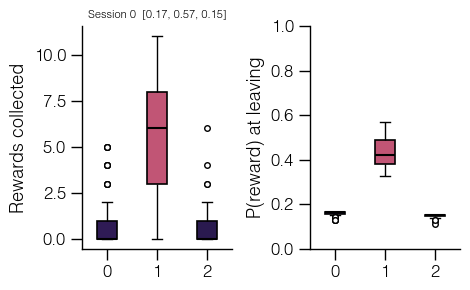

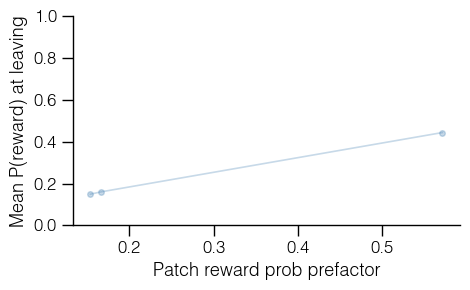

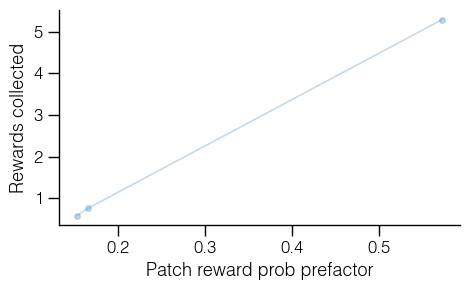

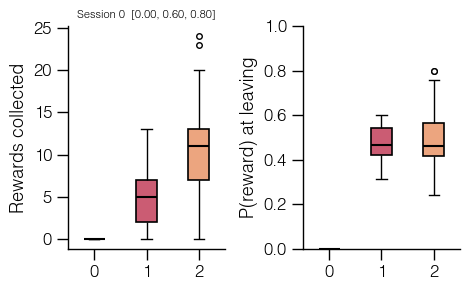

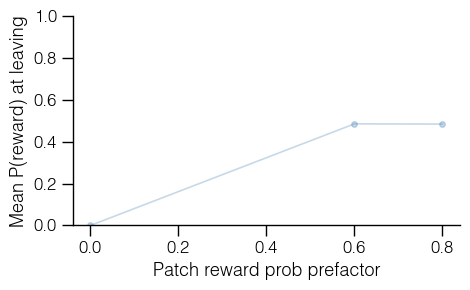

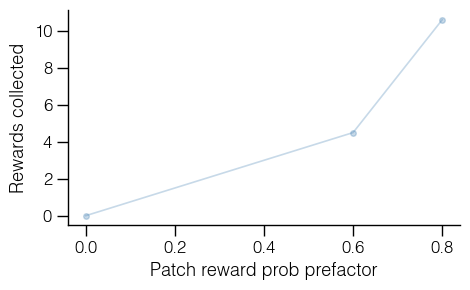

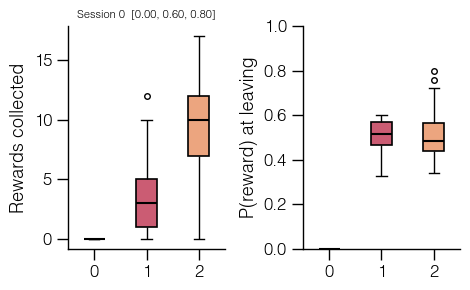

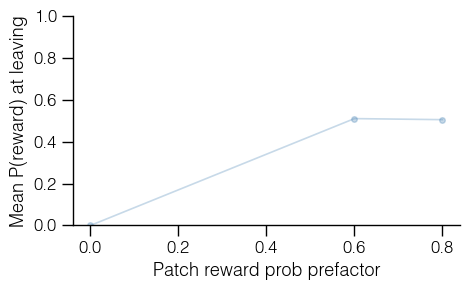

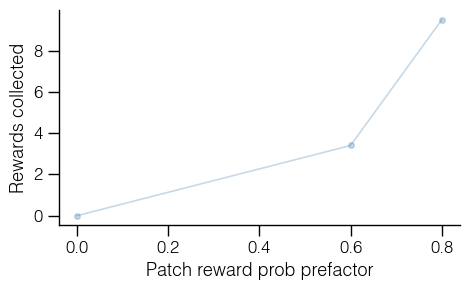

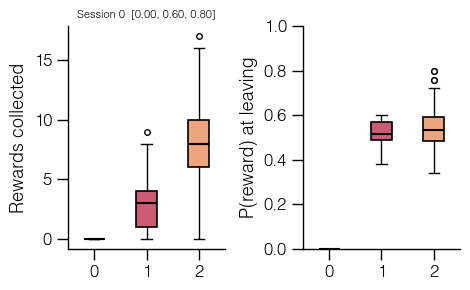

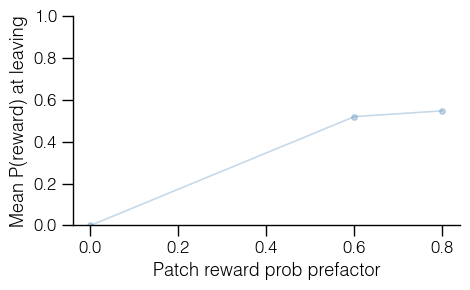

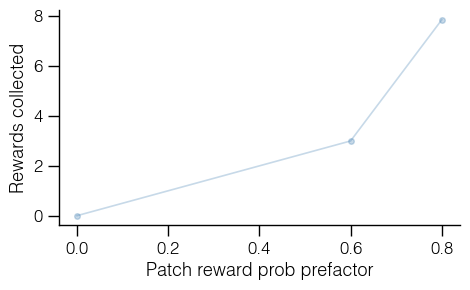

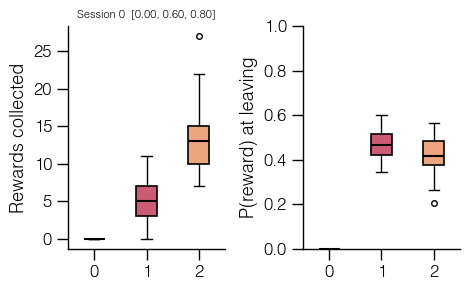

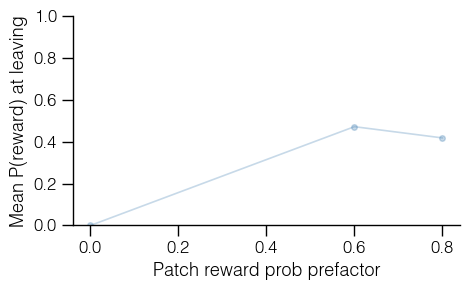

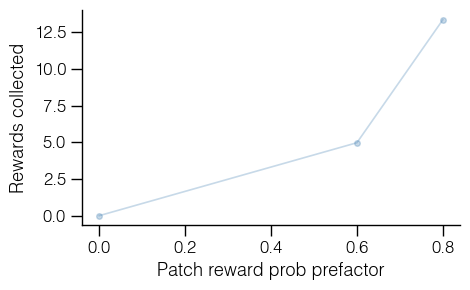

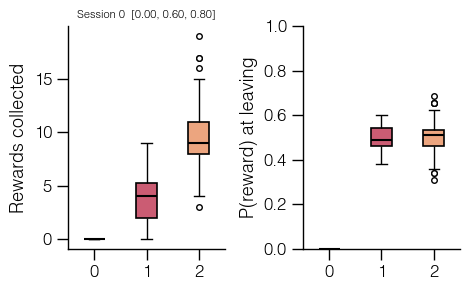

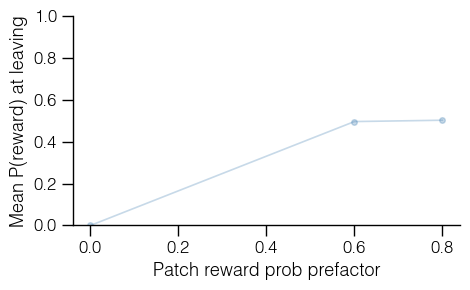

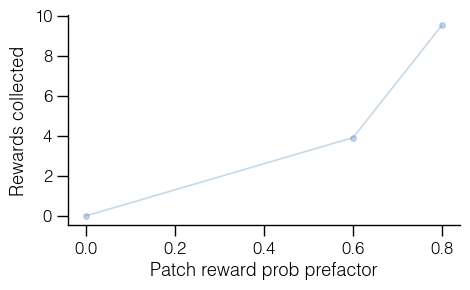

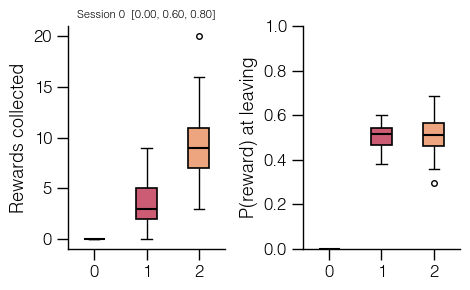

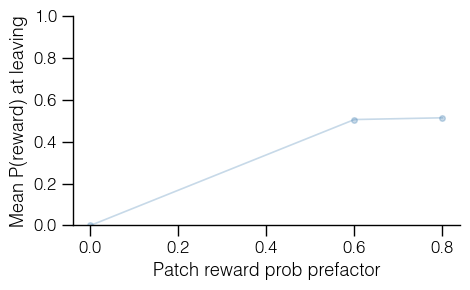

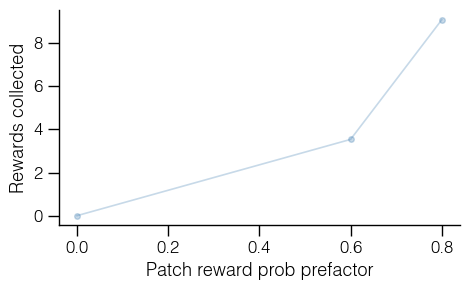

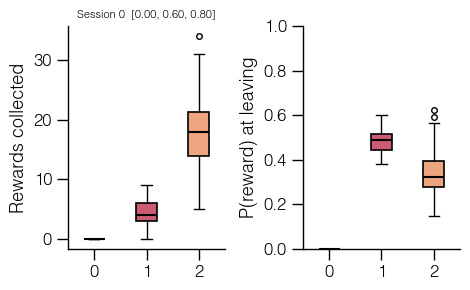

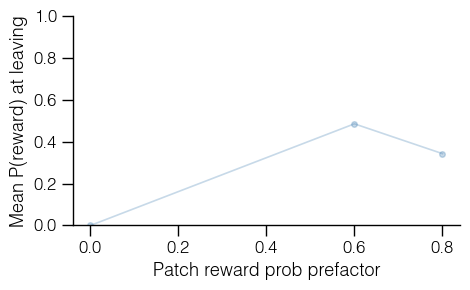

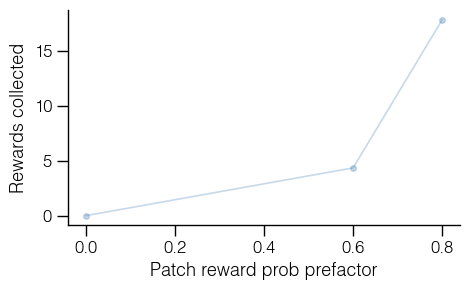

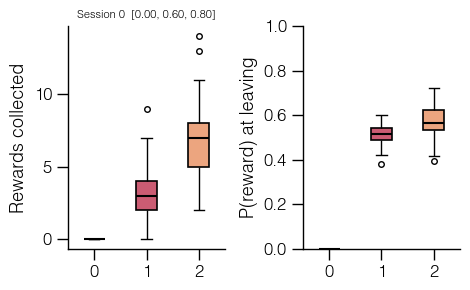

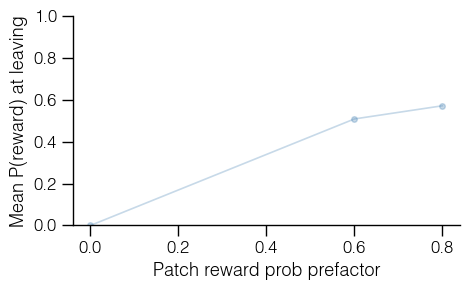

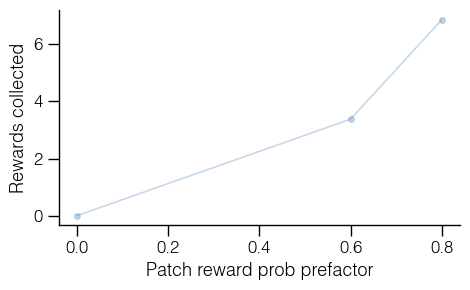

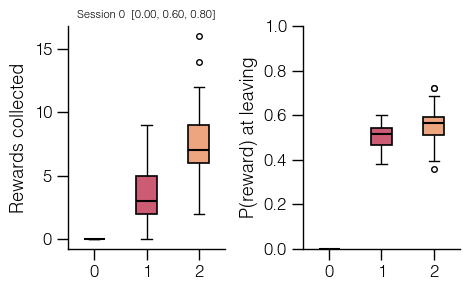

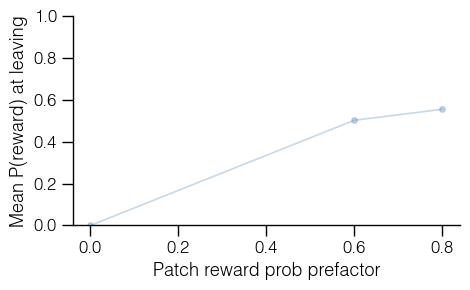

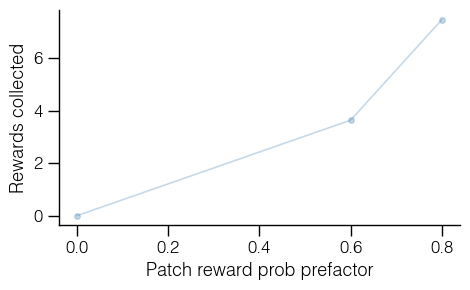

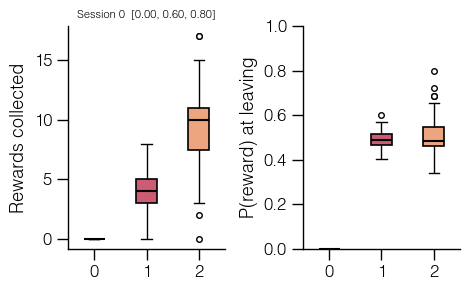

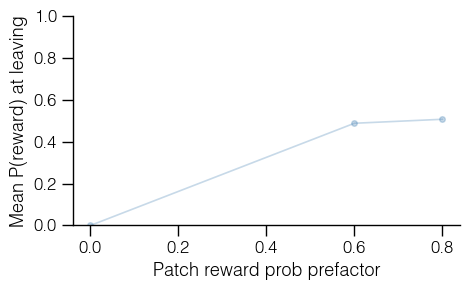

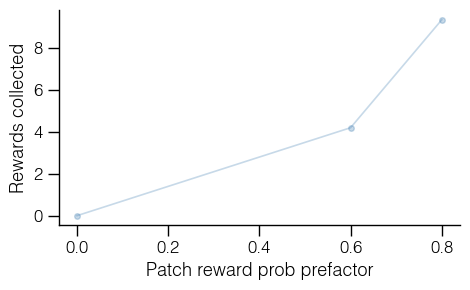

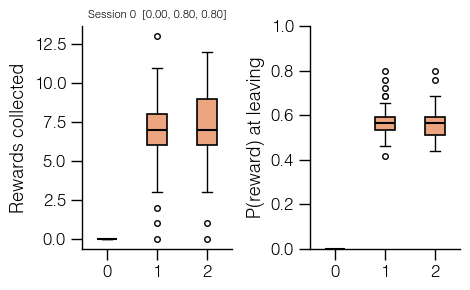

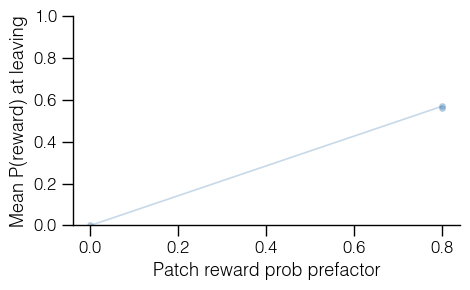

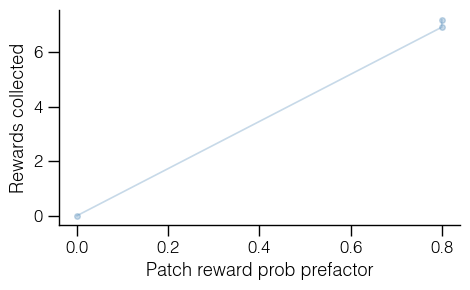

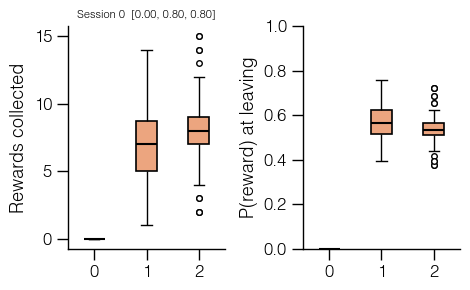

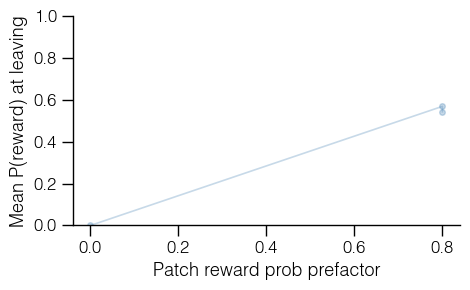

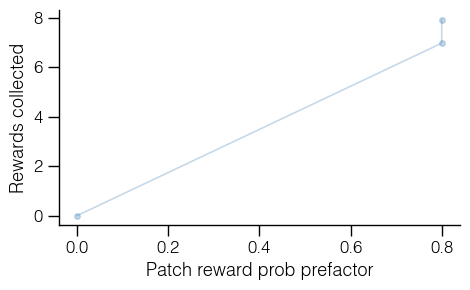

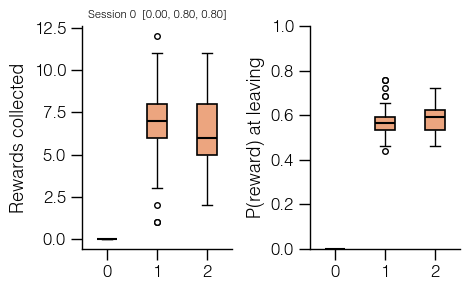

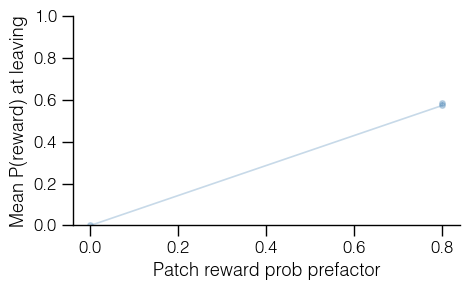

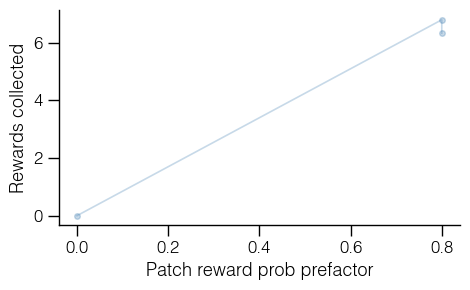

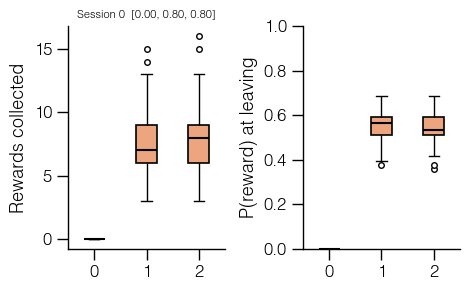

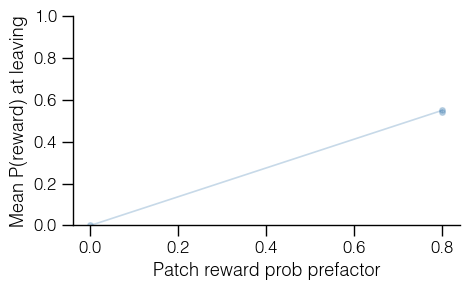

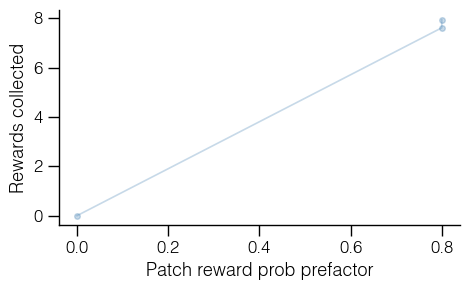

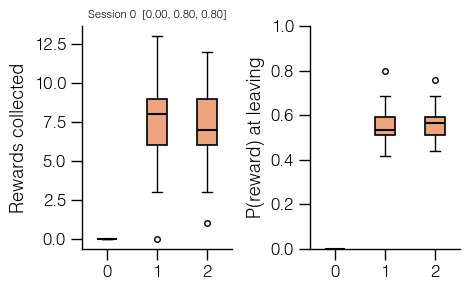

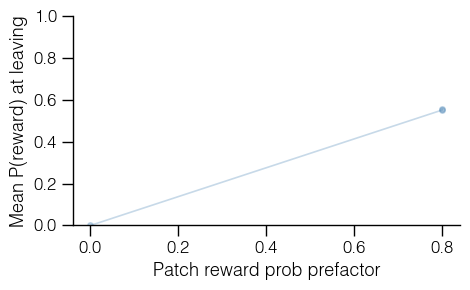

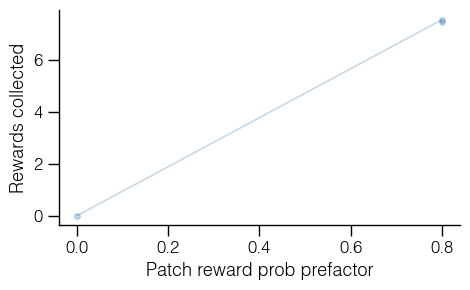

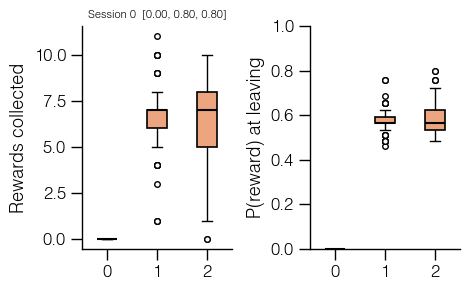

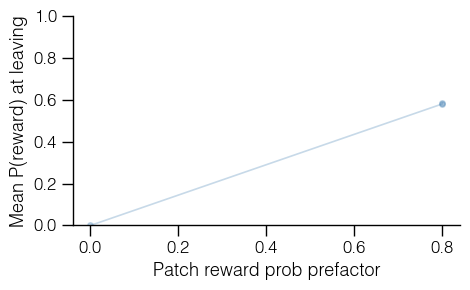

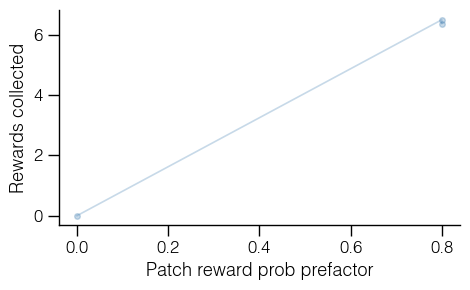

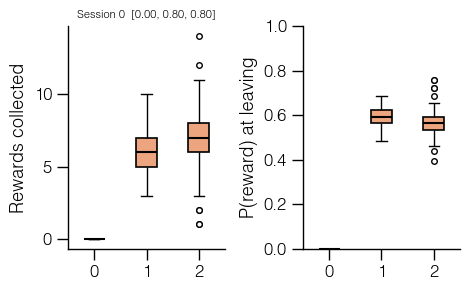

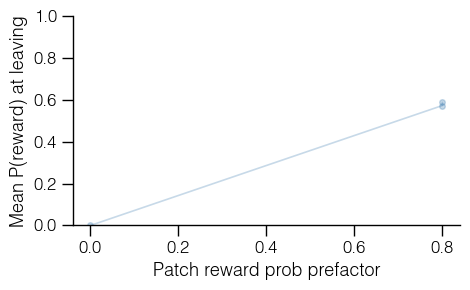

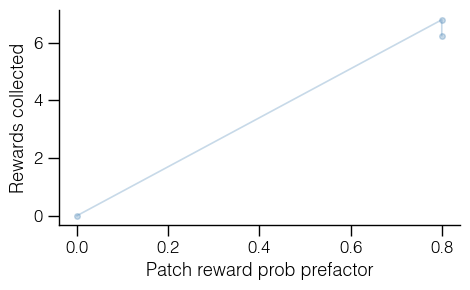

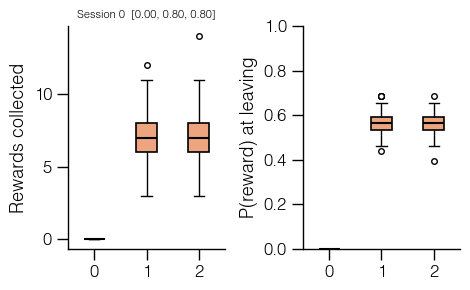

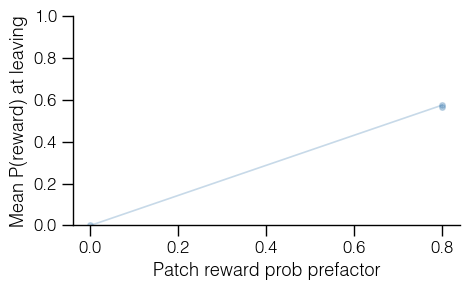

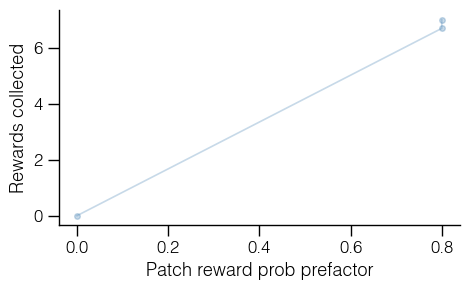

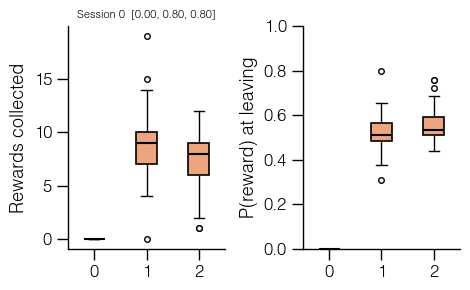

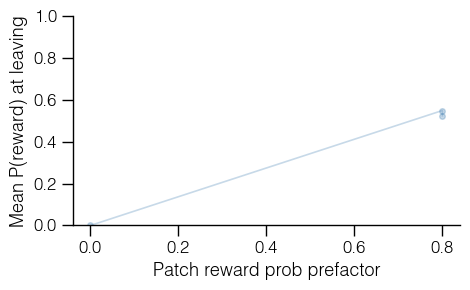

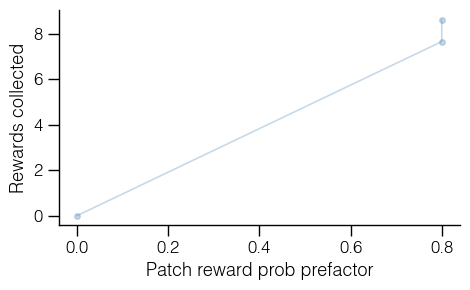

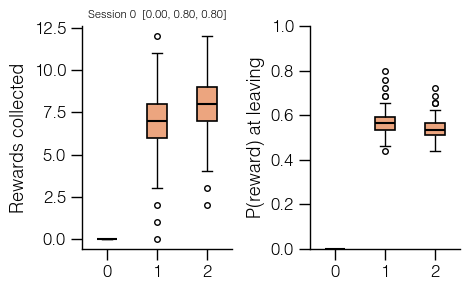

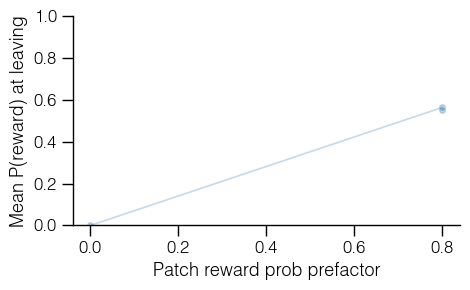

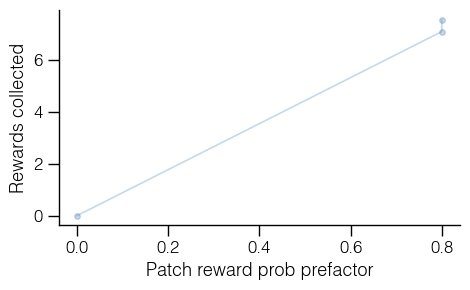

In [39]:
for df in dfs_fixed_to_equal_high:
    plot_patch_statistics_per_session(
        df,
        ylim_right=[0, 1.],
        
        
    )

In [ ]:
for df in dfs:
    plot_patch_statistics_per_session(
        df,
        ylim_right=[0, 1.],
    )

Processing 0 sessions...
Processing 5 sessions...
Processing 10 sessions...
Processing 15 sessions...
Processing 20 sessions...
Processing 25 sessions...
Processing 30 sessions...
Processing 35 sessions...
Processing 40 sessions...
Processing 45 sessions...


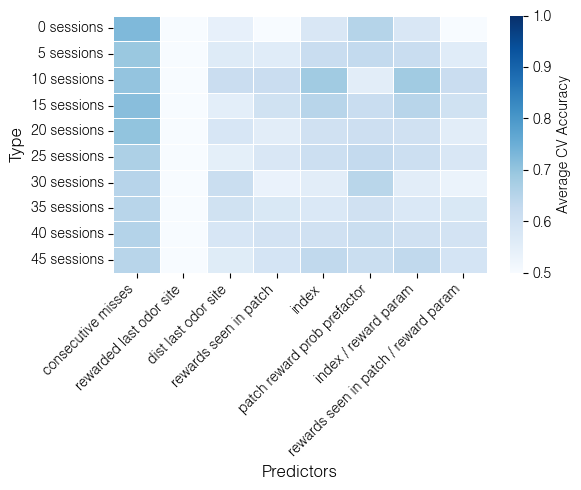

In [44]:
plot_multi_df_accuracy_heatmap(
    [df[df['index'] > 0] for df in dfs],
    [
        'consecutive_misses',
        'rewarded_last_odor_site',
        'dist_last_odor_site',
        'rewards_seen_in_patch',
        'index',
        'patch_reward_prob_prefactor',
        'index / reward_param',
        'rewards_seen_in_patch / reward_param',
    ],
    df_labels=[f'{x} sessions' for x in np.arange(0, 50, 5)],
    figsize=(6, 5),
)

Processing 0 0.6 0.8 - session 0...
Processing 0 0.6 0.8 - session 15...
Processing 0.8 0 0.6 - session 0...
Processing 0.8 0 0.6 - session 15...
Processing 0.6 0.8 0 - session 0...
Processing 0.6 0.8 0 - session 15...
Processing 0 0.6 0.8 - session 0...
Processing 0 0.6 0.8 - session 15...


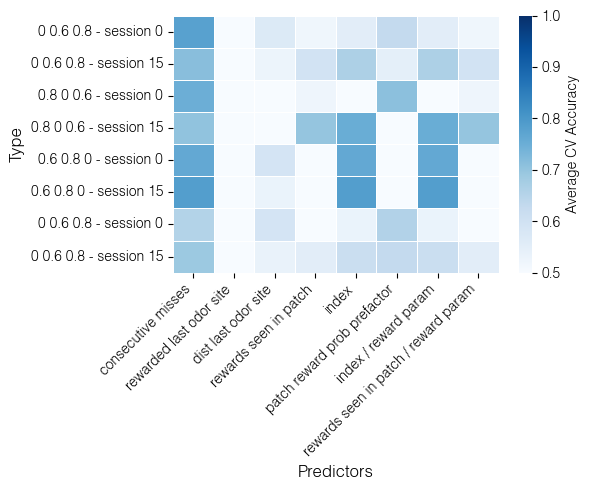

In [43]:
plot_multi_df_accuracy_heatmap(
    [df[df['index'] > 0] for df in dfs_multistage_cycle],
    [
        'consecutive_misses',
        'rewarded_last_odor_site',
        'dist_last_odor_site',
        'rewards_seen_in_patch',
        'index',
        'patch_reward_prob_prefactor',
        'index / reward_param',
        'rewards_seen_in_patch / reward_param',
    ],
    df_labels=[
        '0 0.6 0.8 - session 0',
        '0 0.6 0.8 - session 15',
        '0.8 0 0.6 - session 0',
        '0.8 0 0.6 - session 15',
        '0.6 0.8 0 - session 0',
        '0.6 0.8 0 - session 15',
        '0 0.6 0.8 - session 0',
        '0 0.6 0.8 - session 15',
    ],
    figsize=(6, 5),
)

Processing Randomized 499...
Processing Fixed 500...
Processing Fixed 510...
Processing Fixed 520...
Processing Fixed 530...
Processing Fixed 540...
Processing Fixed 550...
Processing Fixed 560...
Processing Fixed 570...
Processing Fixed 580...
Processing Fixed 590...
Processing Equal low 600...
Processing Equal low 610...
Processing Equal low 620...
Processing Equal low 630...
Processing Equal low 640...
Processing Equal low 650...
Processing Equal low 660...
Processing Equal low 670...
Processing Equal low 680...
Processing Equal low 690...


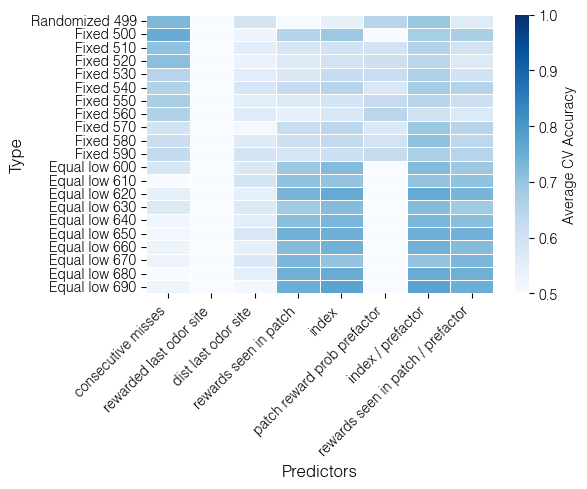

In [47]:
def gen_mask(df):
    return (df['index'] > 0) & (df['patch_type'] > 0)

plot_multi_df_accuracy_heatmap(
    [df[gen_mask(df)] for df in dfs_fixed_to_equal_low],
    [
        'consecutive_misses',
        'rewarded_last_odor_site',
        'dist_last_odor_site',
        'rewards_seen_in_patch',
        'index',
        'patch_reward_prob_prefactor',
        'index / prefactor',
        'rewards_seen_in_patch / prefactor',
    ],
    df_labels=['Randomized 499'] + [f'Fixed {s}' for s in np.arange(500, 600, 10)] + [f'Equal low {s}' for s in np.arange(600, 700, 10)],
    figsize=(6, 5),
)

Processing Randomized 499...
Processing Fixed 500...
Processing Fixed 510...
Processing Fixed 520...
Processing Fixed 530...
Processing Fixed 540...
Processing Fixed 550...
Processing Fixed 560...
Processing Fixed 570...
Processing Fixed 580...
Processing Fixed 590...
Processing Equal high 600...
Processing Equal high 610...
Processing Equal high 620...
Processing Equal high 630...
Processing Equal high 640...
Processing Equal high 650...
Processing Equal high 660...
Processing Equal high 670...
Processing Equal high 680...
Processing Equal high 690...


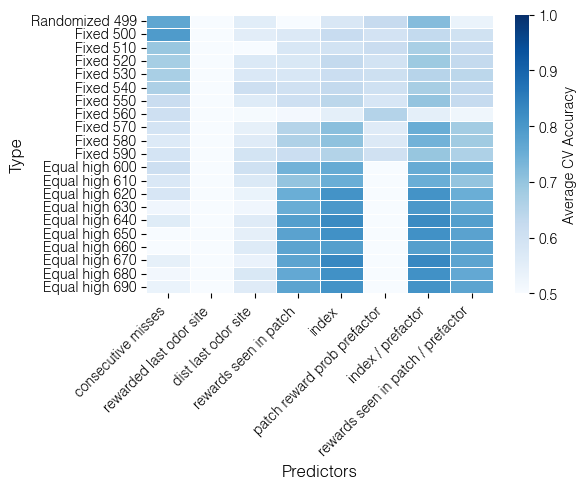

In [46]:
def gen_mask(df):
    return (df['index'] > 0) & (df['patch_type'] > 0)

plot_multi_df_accuracy_heatmap(
    [df[gen_mask(df)] for df in dfs_fixed_to_equal_high],
    [
        'consecutive_misses',
        'rewarded_last_odor_site',
        'dist_last_odor_site',
        'rewards_seen_in_patch',
        'index',
        'patch_reward_prob_prefactor',
        'index / prefactor',
        'rewards_seen_in_patch / prefactor',
    ],
    df_labels=['Randomized 499'] + [f'Fixed {s}' for s in np.arange(500, 600, 10)] + [f'Equal high {s}' for s in np.arange(600, 700, 10)],
    figsize=(6, 5),
)

Processing Randomized 249...
Processing Randomized 299...
Processing Randomized 349...
Processing Randomized 399...
Processing Randomized 449...
Processing Randomized 499...
Processing Fixed 500...
Processing Fixed 550...
Processing Fixed 600...
Processing Fixed 650...
Processing Fixed 700...
Processing Fixed 750...
Processing Fixed 800...
Processing Fixed 850...
Processing Fixed 900...
Processing Fixed 950...


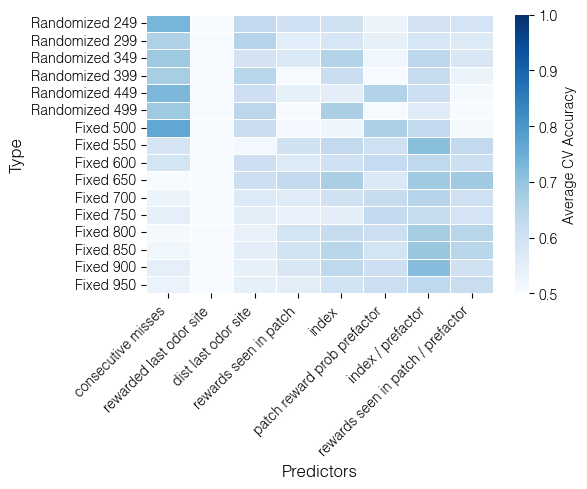

In [80]:
def gen_mask(df):
    return (df['index'] > 0) # & (df['patch_type'] > 0)

plot_multi_df_accuracy_heatmap(
    [df[gen_mask(df)] for df in dfs_coupled_to_fixed_v2],
    [
        'consecutive_misses',
        'rewarded_last_odor_site',
        'dist_last_odor_site',
        'rewards_seen_in_patch',
        'index',
        'patch_reward_prob_prefactor',
        'index / prefactor',
        'rewards_seen_in_patch / prefactor',
    ],
    df_labels=[f'Randomized {s}' for s in np.arange(249, 500, 50)] + [f'Fixed {s}' for s in np.arange(500, 1000, 50)],
    figsize=(6, 5),
)

## Accumulated reward against consecutive failures

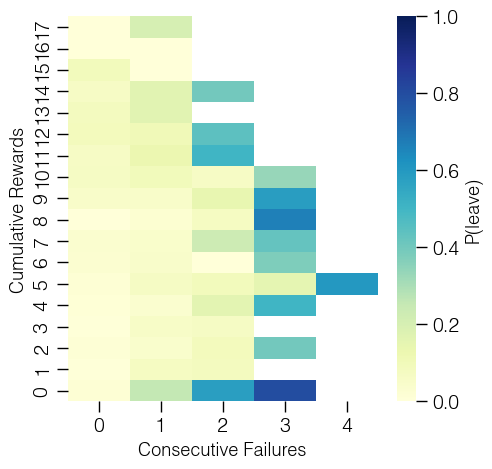

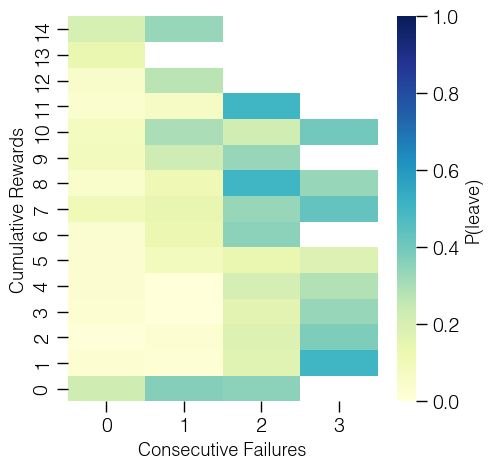

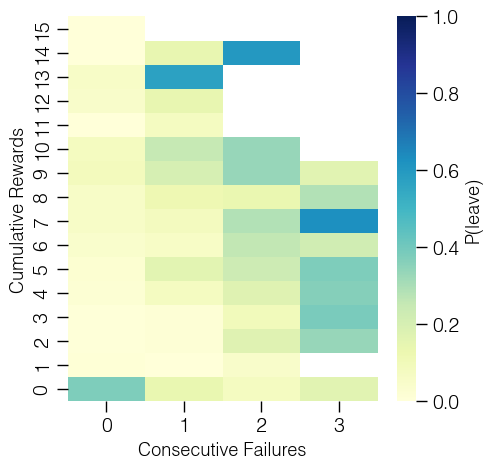

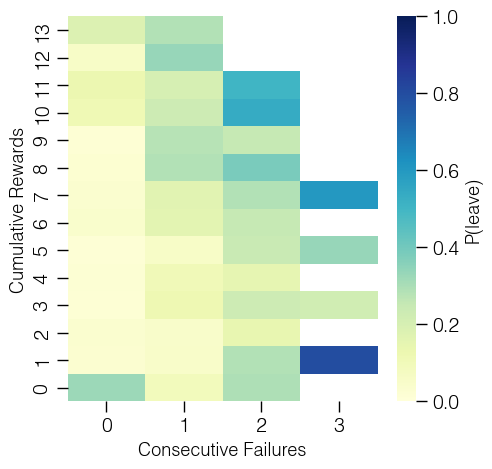

In [ ]:
for df in dfs:
    plot_stop_fraction(
        df,
        'consecutive_misses',
        'rewards_seen_in_patch',
        invert_y=True,
        figsize=(5, 5),
        reverse=True,
        xlabel='Consecutive Failures',
        ylabel='Cumulative Rewards',
        min_n=5,
    )
None